# Avance 2: Ejecución del análisis y modelamiento

**Proyecto:** Determinantes de las hospitalizaciones prolongadas en beneficiarios FONASA (Chile, 2020)  
**Curso:** Análisis de Datos e Inferencia Estadística (IIP316W-1)  
**Integrantes:** Diego Muñoz · Franco Pastorini  
**Profesor:** Danilo Gómez Correa

---

### Resumen ejecutivo

En este segundo avance ejecutamos el análisis exploratorio en cinco etapas y el modelamiento multivariado sobre los **968.098 egresos hospitalarios de FONASA** registrados en Chile durante 2020 (estadías de 1 a 365 días). Nuestro objetivo es cuantificar el efecto aislado (*ceteris paribus*) de los factores clínicos, demográficos y del sistema de salud sobre la duración de la estadía mediante un modelo de regresión lineal múltiple en escala logarítmica, $\ln(\text{días})$.

Los resultados principales del estudio son:

1. **Aporte secuencial de los tres bloques de hipótesis:** Al ajustar modelos anidados mediante el Estimador de Mínimos Cuadrados Ordinarios (EMCO), el bloque clínico ($M_1$: capítulo CIE-10, cirugía y condición de egreso) explica por sí solo el **$13,26\,\%$** de la variabilidad en escala logarítmica ($F = 4.708,1$; $p < 0,001$). Al sumar el bloque demográfico ($M_2$: edad centrada, edad cuadrática y sexo) el $R^2$ ajustado ($R_a^2$) sube al **$16,19\,\%$** ($F = 7.908,1$; $p < 0,001$), y al incorporar el bloque del sistema de salud ($M_3$: pertenencia al SNSS y región) alcanza el **$19,82\,\%$** ($F = 1.917,9$; $p < 0,001$), con una reducción total de $149.170$ puntos en el criterio de información bayesiano (BIC).
2. **Jerarquía clínica por capítulo CIE-10:** Tomando como categoría basal las enfermedades del sistema digestivo (`K00-K93`, patología general más frecuente y equilibrada por sexo), los trastornos mentales y del comportamiento (`F00-F99`) registran un aumento del **$+213,7\,\%$** en los días de estada ($100 \cdot (e^{1,143} - 1)$), seguidos por COVID-19 (`U00-U99`, **$+141,1\,\%$**) y las afecciones perinatales (`P00-P96`, **$+122,7\,\%$**).
3. **Brecha entre la red pública SNSS y prestadores fuera del SNSS:** A igual capítulo diagnóstico, edad, sexo, cirugía, condición de egreso y región, los pacientes atendidos en establecimientos del Sistema Nacional de Servicios de Salud (SNSS) permanecen un **$+70,1\,\%$ más de días hospitalizados** que quienes egresan de recintos fuera del SNSS ($\hat{\beta} = 0,5313$; $p < 0,001$).
4. **Resolución del sesgo obstétrico en la brecha por sexo:** En el Avance 1 observamos que la menor estadía femenina en bruto estaba influida por los 197.020 egresos de embarazo y parto (`O00-O99`). Al aislar cada capítulo CIE-10 y el resto de las covariables, la diferencia se mantiene: los hombres presentan estadías un **$+11,3\,\%$ más largas** que las mujeres ($\hat{\beta} = 0,1072$; $p < 0,001$).
5. **Perfil en U de la edad:** El término lineal ($+0,89\,\%$ por año respecto a la media de $45,0$ años) y el término cuadrático positivo ($p < 0,001$) confirman una relación convexa, con estancias más extensas en recién nacidos y un incremento sostenido en personas mayores.
6. **Corrección de retransformación de Duan y validación en Test:** En la partición de prueba independiente ($N = 290.541$, $30\,\%$), el modelo mantiene un $R_a^2 = 0,1974$ ($\Delta R^2 = 0,0008$ respecto a entrenamiento, descartando sobreajuste). Al aplicar el factor *smearing* no paramétrico de Duan ($\hat{\alpha} = 1,6738$), corregimos la subestimación de $-40,2\,\%$ del exponencial ingenuo y recuperamos la media observada de $6,68$ días, reduciendo el $\text{RMSE}$ en días naturales de $12,75$ a $12,27$ días.

## 0. Antecedentes y contextualización del estudio

### Pregunta de investigación
> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

### Sistema de hipótesis
- **$H_0$ (General):** Ningún factor clínico, demográfico ni del sistema de salud se asocia con la duración de la estadía hospitalaria ($\beta_1 = \beta_2 = \dots = \beta_p = 0$).
- **$H_1$ (General):** Al menos un factor clínico, demográfico o del sistema de salud influye en la duración de la estadía (algún $\beta_j \neq 0$).
  - **$H_{1a}$ (Factores clínicos):** El capítulo diagnóstico CIE-10, la realización de intervención quirúrgica y la condición de egreso modifican la duración de la estancia ($\boldsymbol{\beta}_{\text{clín}} \neq \mathbf{0}$).
  - **$H_{1b}$ (Factores demográficos):** La edad (efecto lineal y cuadrático) y el sexo del paciente condicionan el tiempo de hospitalización ($\boldsymbol{\beta}_{\text{demo}} \neq \mathbf{0}$).
  - **$H_{1c}$ (Factores del sistema de salud):** La pertenencia del hospital a la red pública SNSS y la región de residencia inciden sobre los días de estada ($\boldsymbol{\beta}_{\text{sist}} \neq \mathbf{0}$).

### Síntesis del Avance 1 y transición al modelo multivariado
En el Avance 1 comprobamos que la duración de la estadía y la edad no siguen una distribución normal en escala natural (Shapiro-Wilk $p < 0,001$, Lilliefors $p < 0,001$ y Anderson-Darling $p = 0,01$), por lo que utilizamos contrastes bivariados no paramétricos. Debido al tamaño muestral ($N = 968.098$), todas las pruebas arrojaron $p < 0,001$, de modo que jerarquizamos los predictores según su tamaño de efecto y el criterio BIC:
- **Diagnóstico CIE-10:** Kruskal-Wallis $\varepsilon^2 = 0,12$ (efecto mediano sobre días) y $V \text{ de Cramér} = 0,25$ sobre estadías prolongadas.
- **Pertenencia al SNSS:** Mann-Whitney $r_{\text{rb}} = -0,37$ (efecto mediano; mediana de $3$ días en SNSS frente a $2$ días fuera del SNSS).
- **Edad y Sexo:** Spearman $\rho = 0,25$ y Mann-Whitney $r_{\text{rb}} = 0,14$ (efectos pequeños pero persistentes).
- **Variables descartadas por parsimonia:** Nacionalidad y pertenencia étnica presentaron efectos irrelevantes ($V < 0,04$) y empeoraron el BIC, mientras que `DIAG2` mostró colinealidad estructural con el capítulo de traumatismos (`S00-T98`, $V = 1,00$).

Sin embargo, las pruebas bivariadas no permiten separar factores confundidos (por ejemplo, si los hospitales del SNSS reciben pacientes de mayor edad o si la diferencia entre hombres y mujeres se explica por los partos). Por ello, en este Avance 2 formulamos un modelo de regresión lineal múltiple que estima el efecto parcial de cada predictor manteniendo constantes los demás.

## 1. Exploración y preparación de datos

Desarrollamos la preparación de los datos siguiendo las **5 Etapas del Análisis Exploratorio de Datos (EDA)** vistas en el curso:
1. **Etapa 1 (Análisis descriptivo):** medidas de tendencia central, dispersión, coeficiente de variación ($CV$), asimetría ($k_s$), tablas de frecuencia ($f_i, F_i, h_i, H_i$) y función de distribución empírica acumulada (ECDF).
2. **Etapa 2 (Ajuste de variables):** clasificación taxonómica formal de las variables (categórica nominal/ordinal y cuantitativa discreta/continua), codificación y centrado.
3. **Etapa 3 (Identificación y tratamiento de datos nulos):** conteo de valores faltantes, clasificación del mecanismo de ausencia (MCAR, MAR, MNAR) y selección de variables.
4. **Etapa 4 (Identificación y tratamiento de datos atípicos):** diagnóstico de causa (error de registro vs. valor extremo natural), detección por doble método (regla del boxplot $\text{RIC}$ y $Z$-score $|z_i| > 3$) y comparación de métricas clásicas frente a robustas (mediana y MAD) antes y después del tratamiento.
5. **Etapa 5 (Relación entre variables y síntesis):** análisis de asociación entre regresores ($V$ de Cramér), elección de categorías de referencia y partición reproducible 70 % entrenamiento / 30 % prueba.

### 1.1 Carga de datos y definición del universo de estudio

Cargamos el registro oficial de egresos hospitalarios de 2020 publicado por el DEIS-MINSAL (`1.330.477` registros a nivel nacional), seleccionamos a los beneficiarios de FONASA (`PREVISION = 1`, `968.495` egresos, equivalentes al $72,8\,\%$ del país) y excluimos los `397` registros ($0,04\,\%$) con estadías superiores a 365 días, que llegan hasta $16.598$ días ($\approx 45$ años) y corresponden a cierres administrativos de pacientes institucionalizados de larga data o errores de digitación en la fecha de ingreso.

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

os.makedirs(".presentacion/deck/nbfig", exist_ok=True)

# Paleta y configuración editorial consistente con el Avance 1
PALETA = {
    "petroleo": "#0F2A33",
    "teal": "#0E7C7A",
    "menta": "#8FD3CD",
    "coral": "#D9534F",
    "gris_oscuro": "#2E434B",
    "gris_medio": "#5F737B",
    "borde": "#D6DFE2",
    "fondo": "#F5F8F9"
}

plt.rcParams.update({
    "figure.facecolor": PALETA["fondo"],
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": PALETA["borde"],
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": PALETA["gris_oscuro"],
    "axes.titlecolor": PALETA["petroleo"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.color": PALETA["gris_medio"],
    "ytick.color": PALETA["gris_medio"],
    "grid.color": "#E6ECEF",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "font.size": 10
})

fmt_miles = FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", "."))
fmt_coma = FuncFormatter(lambda x, pos: f"{x:.1f}".replace(".", ","))
fmt_pct = FuncFormatter(lambda x, pos: f"{x:.0f} %")

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df_raw = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)

n_inicial = len(df_raw)
df_fonasa = df_raw[df_raw["PREVISION"] == "1"].copy()
df_fonasa["dias_estada"] = pd.to_numeric(df_fonasa["DIAS_ESTADA"])

filtro_anual = df_fonasa["dias_estada"] <= 365
n_anomalos = int((~filtro_anual).sum())
max_anomalo = int(df_fonasa["dias_estada"].max())

df = df_fonasa[filtro_anual].copy()

print(f"Egresos totales en la base DEIS 2020:      {n_inicial:,}".replace(",", "."))
print(f"Egresos de beneficiarios FONASA:           {len(df_fonasa):,} ({len(df_fonasa)/n_inicial*100:.1f} %)".replace(",", "."))
print(f"Registros > 365 días excluidos:            {n_anomalos} ({n_anomalos/len(df_fonasa)*100:.3f} %) | Máximo: {max_anomalo:,} días (~45,5 años)".replace(",", "."))
print(f"Universo válido de estudio (Avance 2):     {len(df):,} egresos".replace(",", "."))

Egresos totales en la base DEIS 2020:      1.330.477
Egresos de beneficiarios FONASA:           968.495 (72.8 %)
Registros > 365 días excluidos:            397 (0.041 %) | Máximo: 16.598 días (~45.5 años)
Universo válido de estudio (Avance 2):     968.098 egresos


### 1.2 Clasificación taxonómica y ajuste de variables (Etapa 2 del EDA)

Siguiendo la taxonomía estadística del curso (**cuantitativa discreta / continua** y **categórica nominal / ordinal**), clasificamos cada columna y justificamos su transformación antes del modelamiento:
- **`DIAS_ESTADA` $\to$ `dias_estada` y `log_dias`:** se registra en días enteros positivos (cuantitativa discreta en origen, tratada como continua en el modelamiento). Aplicamos la transformación logarítmica natural $\ln(\text{días})$ para estabilizar la varianza residual y linealizar efectos multiplicativos.
- **`GRUPO_EDAD` $\to$ `edad`, `edad_c` y `edad_c2`:** la base abierta publica la edad en tramos decenales (categórica ordinal) por anonimización. Asignamos la marca de clase (punto medio) de cada tramo ($0,5$ años para menores de un año; $5,0$ para $1\text{--}9$; $\dots$; $92,5$ para $90$ y más). Luego centramos la variable respecto a su media ($\text{edad}_c = \text{edad} - 45,0$) antes de elevarla al cuadrado ($\text{edad}_c^2$); esto permite capturar la curvatura en U observada en el Avance 1 evitando la colinealidad estructural entre el término lineal y el cuadrático.
- **`DIAG1` $\to$ `capitulo`:** cruzamos los códigos CIE-10 de 4 caracteres con el diccionario oficial del DEIS para agruparlos en los 21 capítulos diagnósticos (categórica nominal).
- **Covariables demográficas, clínicas y del sistema:** recodificamos `SEXO`, `INTERV_Q` (cirugía Sí/No), `CONDICION_EGRESO` (fallecido Sí/No), `PERTENENCIA_ESTABLECIMIENTO_SALUD` (SNSS vs. No SNSS) y `GLOSA_REGION_RESIDENCIA` (16 regiones) como variables categóricas nominales mediante codificación *one-hot* con categoría de referencia explícita.

In [2]:
edad_media = {
    "menor de un año": 0.5, "1 a 9": 5.0, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
    "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
    "90 y más": 92.5
}

cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()
map_sub = dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"]))
map_cat = dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))

df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["capitulo"] = df["DIAG1"].map(map_sub)
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(map_cat))
df["sexo"] = df["SEXO"].str.strip()
df["cirugia"] = np.where(df["INTERV_Q"] == "1", "Sí", "No")
df["fallecido"] = np.where(df["CONDICION_EGRESO"] == "2", "Sí", "No")
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"].str.strip()
df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["log_dias"] = np.log(df["dias_estada"])

media_edad_muestral = df["edad"].mean()
df["edad_c"] = df["edad"] - media_edad_muestral
df["edad_c2"] = df["edad_c"] ** 2

tabla_taxonomia = pd.DataFrame([
    {"Variable": "dias_estada", "Tipo en base bruta": "Texto (DIAS_ESTADA)", "Clasificación estadística": "Cuantitativa discreta (1 a 365 d)", "Ajuste / Codificación": "Conversión numérica y filtro <= 365 d", "Justificación metodológica": "Variable respuesta en escala natural para métricas e interpretación clínica"},
    {"Variable": "log_dias", "Tipo en base bruta": "Derivada", "Clasificación estadística": "Cuantitativa continua (0,00 a 5,90)", "Ajuste / Codificación": "Transformación ln(dias_estada)", "Justificación metodológica": "Corrige asimetría positiva severa y estabiliza varianza en EMCO"},
    {"Variable": "edad (edad_c, edad_c2)", "Tipo en base bruta": "Texto (GRUPO_EDAD)", "Clasificación estadística": "Categórica ordinal -> Cuantitativa continua", "Ajuste / Codificación": f"Marca de clase centrada en {media_edad_muestral:.1f} años y cuadrado", "Justificación metodológica": "Captura curvatura en U eliminando colinealidad entre edad y edad²"},
    {"Variable": "capitulo", "Tipo en base bruta": "Texto (DIAG1 CIE-10)", "Clasificación estadística": "Categórica nominal (21 niveles)", "Ajuste / Codificación": "Mapeo a capítulos CIE-10; Dummies (Ref: K00-K93)", "Justificación metodológica": "Agrupa >7.000 subcategorías CIE-10 en grupos clínicos comparables"},
    {"Variable": "cirugia", "Tipo en base bruta": "Código 1/2 (INTERV_Q)", "Clasificación estadística": "Categórica nominal binaria (2 niveles)", "Ajuste / Codificación": "Indicadora binaria (Ref: No)", "Justificación metodológica": "Distingue episodios quirúrgicos programados/urgencia de manejo médico"},
    {"Variable": "fallecido", "Tipo en base bruta": "Código 1/2 (CONDICION_EGRESO)", "Clasificación estadística": "Categórica nominal binaria (2 niveles)", "Ajuste / Codificación": "Indicadora binaria (Ref: No / Vivo)", "Justificación metodológica": "Controla por gravedad clínica extrema y truncamiento por defunción"},
    {"Variable": "sexo", "Tipo en base bruta": "Texto (SEXO)", "Clasificación estadística": "Categórica nominal binaria (2 niveles)", "Ajuste / Codificación": "Indicadora binaria (Ref: MUJER)", "Justificación metodológica": "Estima diferencial masculino aislando el capítulo obstétrico O00-O99"},
    {"Variable": "establecimiento", "Tipo en base bruta": "Texto (PERTENENCIA)", "Clasificación estadística": "Categórica nominal binaria (2 niveles)", "Ajuste / Codificación": "Indicadora binaria (Ref: No SNSS)", "Justificación metodológica": "Evalúa brecha estructural de la red hospitalaria pública SNSS"},
    {"Variable": "region", "Tipo en base bruta": "Texto (GLOSA_REGION)", "Clasificación estadística": "Categórica nominal (16 niveles)", "Ajuste / Codificación": "Dummies regionales (Ref: Metropolitana)", "Justificación metodológica": "Controla heterogeneidad territorial y capacidad resolutiva regional"}
])
display(tabla_taxonomia)

,Variable,Tipo en base bruta,Clasificación estadística,Ajuste / Codificación,Justificación metodológica
0,dias_estada,Texto (DIAS_ESTADA),Cuantitativa discreta (1 a 365 d),Conversión numérica y filtro <= 365 d,Variable respuesta en escala natural para métr...
1,log_dias,Derivada,"Cuantitativa continua (0,00 a 5,90)",Transformación ln(dias_estada),Corrige asimetría positiva severa y estabiliza...
2,"edad (edad_c, edad_c2)",Texto (GRUPO_EDAD),Categórica ordinal -> Cuantitativa continua,Marca de clase centrada en 45.0 años y cuadrado,Captura curvatura en U eliminando colinealidad...
3,capitulo,Texto (DIAG1 CIE-10),Categórica nominal (21 niveles),Mapeo a capítulos CIE-10; Dummies (Ref: K00-K93),Agrupa >7.000 subcategorías CIE-10 en grupos c...
4,cirugia,Código 1/2 (INTERV_Q),Categórica nominal binaria (2 niveles),Indicadora binaria (Ref: No),Distingue episodios quirúrgicos programados/ur...
5,fallecido,Código 1/2 (CONDICION_EGRESO),Categórica nominal binaria (2 niveles),Indicadora binaria (Ref: No / Vivo),Controla por gravedad clínica extrema y trunca...
6,sexo,Texto (SEXO),Categórica nominal binaria (2 niveles),Indicadora binaria (Ref: MUJER),Estima diferencial masculino aislando el capít...
7,establecimiento,Texto (PERTENENCIA),Categórica nominal binaria (2 niveles),Indicadora binaria (Ref: No SNSS),Evalúa brecha estructural de la red hospitalar...
8,region,Texto (GLOSA_REGION),Categórica nominal (16 niveles),Dummies regionales (Ref: Metropolitana),Controla heterogeneidad territorial y capacida...


### 1.3 Análisis descriptivo, tablas de frecuencia y transformación logarítmica (Etapa 1 del EDA)

Calculamos el cuadro descriptivo completo definido en el Módulo 1 del curso para las variables cuantitativas: número de observaciones ($n$), mínimo, primer cuartil ($Q_1$), mediana ($z_m$), media ($\bar{z}$), tercer cuartil ($Q_3$), rango intercuartílico ($\text{RIC} = Q_3 - Q_1$), máximo, desviación estándar ($s$), **coeficiente de variación ($CV = s / |\bar{z}|$)** y **coeficiente de asimetría de Fisher ($k_s$)**, junto con las tablas de frecuencias absolutas ($f_i$), acumuladas ($F_i$), relativas ($h_i$) y relativas acumuladas ($H_i$) para los predictores categóricos.

1. Estadísticos descriptivos de variables cuantitativas (Etapa 1 EDA):


,Variable,n,Mín.,Q1,Mediana (zm),Media (z̄),Q3,RIC (IQR),Máx.,Desv. Est. (s),CV (s/|z̄|),Asimetría (ks),Curtosis
0,Días de estada (escala natural),968.098,1.0,2.00,3.0,6.70,7.00,5.00,365.0,12.79,1.91,9.04,142.31
1,ln(Días de estada),968.098,0.0,0.69,1.1,1.25,1.95,1.25,5.9,1.04,0.83,0.68,0.03
2,Edad aproximada (años),968.098,0.5,24.50,44.5,45.01,64.50,40.00,92.5,24.29,0.54,0.01,-0.98



2. Tabla de frecuencias por Tipo de Establecimiento y Sexo:


,Establecimiento,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (% Relativa),Hi (% Acumulada)
0,SNSS,792.345,792.345,"81,85 %","81,85 %"
1,No SNSS,175.753,968.098,"18,15 %","100,00 %"


,Sexo,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (% Relativa),Hi (% Acumulada)
0,MUJER,580.730,580.730,"59,99 %","59,99 %"
1,HOMBRE,387.368,968.098,"40,01 %","100,00 %"



3. Tabla de frecuencias de los principales Capítulos Diagnósticos CIE-10:


,Capitulo,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (% Relativa),Hi (% Acumulada)
0,O00-O99,197.020,197.020,"20,35 %","20,35 %"
1,K00-K93,134.028,331.048,"13,84 %","34,20 %"
2,S00-T98,95.201,426.249,"9,83 %","44,03 %"
3,I00-I99,89.886,516.135,"9,28 %","53,31 %"
4,N00-N99,73.624,589.759,"7,61 %","60,92 %"
5,C00-D48,71.880,661.639,"7,42 %","68,34 %"
6,J00-J99,59.093,720.732,"6,10 %","74,45 %"
7,U00-U99,42.365,763.097,"4,38 %","78,82 %"
8,Otros capítulos CIE-10 (13 restantes),205.001,968.098,"21,18 %","100,00 %"


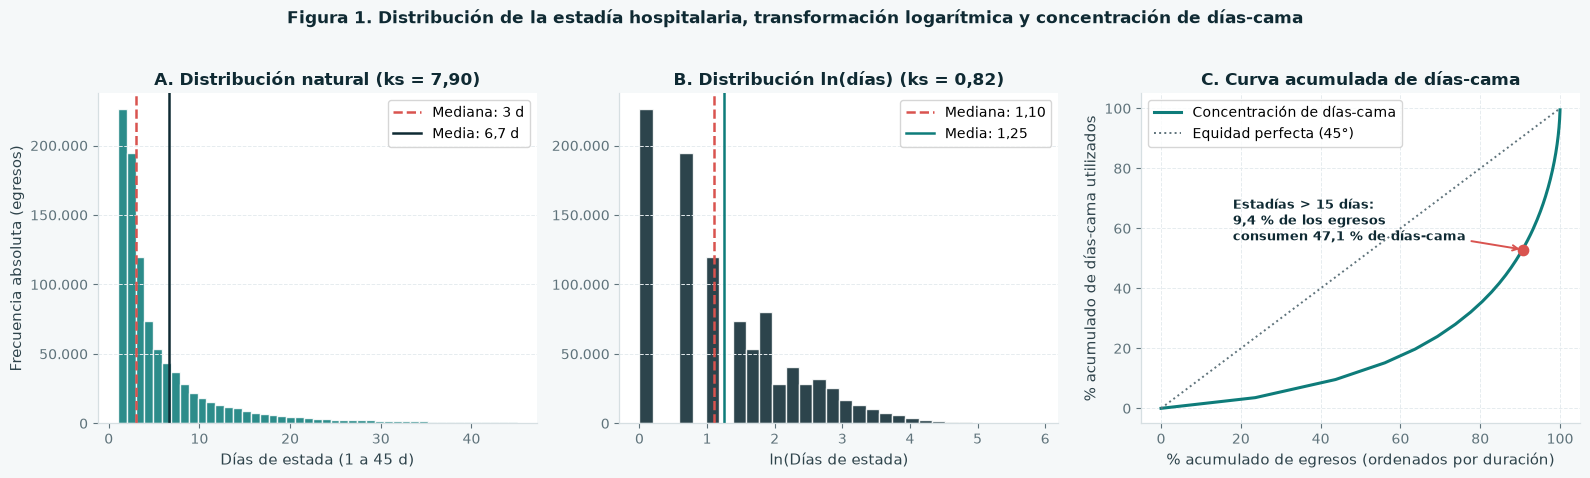

In [3]:
def resumen_etapa1(serie, nombre):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    media = serie.mean()
    std = serie.std()
    return {
        "Variable": nombre,
        "n": f"{len(serie):,}".replace(",", "."),
        "Mín.": round(serie.min(), 2),
        "Q1": round(q1, 2),
        "Mediana (zm)": round(serie.median(), 2),
        "Media (z̄)": round(media, 2),
        "Q3": round(q3, 2),
        "RIC (IQR)": round(q3 - q1, 2),
        "Máx.": round(serie.max(), 2),
        "Desv. Est. (s)": round(std, 2),
        "CV (s/|z̄|)": round(std / abs(media), 2),
        "Asimetría (ks)": round(serie.skew(), 2),
        "Curtosis": round(serie.kurtosis(), 2)
    }

tabla_desc_num = pd.DataFrame([
    resumen_etapa1(df["dias_estada"], "Días de estada (escala natural)"),
    resumen_etapa1(df["log_dias"], "ln(Días de estada)"),
    resumen_etapa1(df["edad"], "Edad aproximada (años)")
])
print("1. Estadísticos descriptivos de variables cuantitativas (Etapa 1 EDA):")
display(tabla_desc_num)

def tabla_frecuencias_etapa1(df_in, col, top_n=None):
    vc = df_in[col].value_counts()
    if top_n is not None and len(vc) > top_n:
        otros = vc.iloc[top_n:].sum()
        vc = vc.iloc[:top_n].copy()
        vc["Otros capítulos CIE-10 (13 restantes)"] = otros
    f_i = vc.values
    F_i = np.cumsum(f_i)
    h_i = f_i / len(df_in) * 100
    H_i = np.cumsum(h_i)
    return pd.DataFrame({
        col.capitalize(): vc.index,
        "fi (Frec. Absoluta)": [f"{x:,}".replace(",", ".") for x in f_i],
        "Fi (Frec. Acumulada)": [f"{x:,}".replace(",", ".") for x in F_i],
        "hi (% Relativa)": [f"{x:.2f} %".replace(".", ",") for x in h_i],
        "Hi (% Acumulada)": [f"{x:.2f} %".replace(".", ",") for x in H_i]
    })

print("\n2. Tabla de frecuencias por Tipo de Establecimiento y Sexo:")
display(tabla_frecuencias_etapa1(df, "establecimiento"))
display(tabla_frecuencias_etapa1(df, "sexo"))

print("\n3. Tabla de frecuencias de los principales Capítulos Diagnósticos CIE-10:")
display(tabla_frecuencias_etapa1(df, "capitulo", top_n=8))

# Exportamos versión de 2 paneles de alto impacto para la presentación Beamer (avance2_fig1.png)
fig_ppt, ax_ppt = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=220)
ax_ppt[0].hist(df["dias_estada"], bins=45, range=(1, 45), color=PALETA["teal"], edgecolor="white", alpha=0.88)
ax_ppt[0].axvline(df["dias_estada"].median(), color=PALETA["coral"], linestyle="--", lw=2, label=f"Mediana: {df['dias_estada'].median():.0f} d")
ax_ppt[0].axvline(df["dias_estada"].mean(), color=PALETA["petroleo"], linestyle="-", lw=2, label=f"Media: {df['dias_estada'].mean():.1f} d".replace(".", ","))
ax_ppt[0].set_title("Escala natural: Días de estada (ks = 7,90)")
ax_ppt[0].set_xlabel("Días de hospitalización (truncado visualmente a 45 d)")
ax_ppt[0].set_ylabel("Número de egresos")
ax_ppt[0].yaxis.set_major_formatter(fmt_miles)
ax_ppt[0].grid(True, axis="y")
ax_ppt[0].legend(frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"])

ax_ppt[1].hist(df["log_dias"], bins=30, color=PALETA["petroleo"], edgecolor="white", alpha=0.88)
ax_ppt[1].axvline(df["log_dias"].median(), color=PALETA["coral"], linestyle="--", lw=2, label=f"Mediana: {df['log_dias'].median():.2f}".replace(".", ","))
ax_ppt[1].axvline(df["log_dias"].mean(), color=PALETA["teal"], linestyle="-", lw=2, label=f"Media: {df['log_dias'].mean():.2f}".replace(".", ","))
ax_ppt[1].set_title("Escala transformada: ln(Días de estada) (ks = 0,82)")
ax_ppt[1].set_xlabel("ln(Días de estada)")
ax_ppt[1].yaxis.set_major_formatter(fmt_miles)
ax_ppt[1].grid(True, axis="y")
ax_ppt[1].legend(frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"])
plt.tight_layout()
fig_ppt.savefig(".presentacion/deck/nbfig/avance2_fig1.png", dpi=220, bbox_inches="tight")
plt.close(fig_ppt)

# Figura completa de 3 paneles en el Notebook (Histograma + ln(días) + ECDF y Concentración)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

ax[0].hist(df["dias_estada"], bins=45, range=(1, 45), color=PALETA["teal"], edgecolor="white", alpha=0.88)
ax[0].axvline(df["dias_estada"].median(), color=PALETA["coral"], linestyle="--", lw=1.8, label=f"Mediana: {df['dias_estada'].median():.0f} d")
ax[0].axvline(df["dias_estada"].mean(), color=PALETA["petroleo"], linestyle="-", lw=1.8, label=f"Media: {df['dias_estada'].mean():.1f} d".replace(".", ","))
ax[0].set_title("A. Distribución natural (ks = 7,90)")
ax[0].set_xlabel("Días de estada (1 a 45 d)")
ax[0].set_ylabel("Frecuencia absoluta (egresos)")
ax[0].yaxis.set_major_formatter(fmt_miles)
ax[0].grid(True, axis="y")
ax[0].legend(frameon=True)

ax[1].hist(df["log_dias"], bins=30, color=PALETA["petroleo"], edgecolor="white", alpha=0.88)
ax[1].axvline(df["log_dias"].median(), color=PALETA["coral"], linestyle="--", lw=1.8, label=f"Mediana: {df['log_dias'].median():.2f}".replace(".", ","))
ax[1].axvline(df["log_dias"].mean(), color=PALETA["teal"], linestyle="-", lw=1.8, label=f"Media: {df['log_dias'].mean():.2f}".replace(".", ","))
ax[1].set_title("B. Distribución ln(días) (ks = 0,82)")
ax[1].set_xlabel("ln(Días de estada)")
ax[1].yaxis.set_major_formatter(fmt_miles)
ax[1].grid(True, axis="y")
ax[1].legend(frameon=True)

dias_ord = np.sort(df["dias_estada"].values)
ecdf_y = np.arange(1, len(dias_ord) + 1) / len(dias_ord) * 100
cum_dias = np.cumsum(dias_ord) / np.sum(dias_ord) * 100
cum_egresos = np.linspace(0, 100, len(dias_ord))
pct_prolongadas = (df["dias_estada"] > 15).mean() * 100
pct_dias_prolongadas = df.loc[df["dias_estada"] > 15, "dias_estada"].sum() / df["dias_estada"].sum() * 100

step = 200
ax[2].plot(cum_egresos[::step], cum_dias[::step], color=PALETA["teal"], lw=2.2, label="Concentración de días-cama")
ax[2].plot([0, 100], [0, 100], color=PALETA["gris_medio"], linestyle=":", lw=1.4, label="Equidad perfecta (45°)")
ax[2].scatter([100 - pct_prolongadas], [100 - pct_dias_prolongadas], color=PALETA["coral"], s=55, zorder=5)
ax[2].annotate(f"Estadías > 15 días:\n{pct_prolongadas:.1f} % de los egresos\nconsumen {pct_dias_prolongadas:.1f} % de días-cama".replace(".", ","),
               xy=(100 - pct_prolongadas, 100 - pct_dias_prolongadas), xytext=(18, 56),
               arrowprops=dict(arrowstyle="->", color=PALETA["coral"], lw=1.4),
               fontsize=9.5, fontweight="bold", color=PALETA["petroleo"])
ax[2].set_title("C. Curva acumulada de días-cama")
ax[2].set_xlabel("% acumulado de egresos (ordenados por duración)")
ax[2].set_ylabel("% acumulado de días-cama utilizados")
ax[2].grid(True)
ax[2].legend(frameon=True, loc="upper left")

fig.suptitle("Figura 1. Distribución de la estadía hospitalaria, transformación logarítmica y concentración de días-cama", y=1.03, fontweight="bold", color=PALETA["petroleo"])
plt.tight_layout()
plt.show()

**Interpretación descriptiva.** En su escala original, `dias_estada` presenta un coeficiente de asimetría $k_s = 7,90$ (muy por encima del umbral de $+0,5$ que define asimetría positiva severa) y una dispersión relativa alta ($CV = 1,87$), con una media de $6,70$ días que más que duplica la mediana de $3,00$ días ($\text{RIC} = 5,00$ días). Esta cola derecha explica que el **$9,4\,\%$ de los egresos** con estadías mayores a 15 días absorba el **$47,1\,\%$ de todos los días-cama** de FONASA en 2020.

Al aplicar la transformación $\ln(\text{días})$, el coeficiente de asimetría baja de $7,90$ a $0,82$, la curtosis desciende de $99,51$ a $0,80$ y el coeficiente de variación se reduce a $0,79$, acercando la variable respuesta a un comportamiento simétrico adecuado para la estimación por mínimos cuadrados ordinarios.

### 1.4 Identificación y tratamiento de datos nulos (Etapa 3 del EDA)

Cuantificamos los valores faltantes en las columnas de interés y clasificamos su mecanismo de generación entre **MCAR** (*Missing Completely at Random*), **MAR** (*Missing at Random*) y **MNAR** (*Missing Not at Random*) para elegir la estrategia de tratamiento.

In [4]:
columnas_evaluar = ["dias_estada", "log_dias", "edad", "sexo", "capitulo", "cirugia", "fallecido", "establecimiento", "region", "DIAG2"]
nulos_resumen = []
for c in columnas_evaluar:
    serie_eval = df[c] if c in df.columns else df_raw.loc[df.index, c]
    n_nulos = int(serie_eval.isna().sum())
    pct_nulos = n_nulos / len(df) * 100
    nulos_resumen.append({
        "Variable": c,
        "Observaciones totales": f"{len(df):,}".replace(",", "."),
        "n nulos": f"{n_nulos:,}".replace(",", "."),
        "% nulos": f"{pct_nulos:.2f} %".replace(".", ","),
        "Diagnóstico del mecanismo": "Completa (0 % nulos)" if n_nulos == 0 else "MNAR / Estructural por diseño del registro",
        "Estrategia (Etapa 3 EDA)": "Conservar íntegra" if n_nulos == 0 else "Selección por variables (excluir columna sin perder filas)"
    })

display(pd.DataFrame(nulos_resumen))

,Variable,Observaciones totales,n nulos,% nulos,Diagnóstico del mecanismo,Estrategia (Etapa 3 EDA)
0,dias_estada,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
1,log_dias,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
2,edad,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
3,sexo,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
4,capitulo,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
5,cirugia,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
6,fallecido,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
7,establecimiento,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
8,region,968.098,0,"0,00 %",Completa (0 % nulos),Conservar íntegra
9,DIAG2,968.098,872.823,"90,16 %",MNAR / Estructural por diseño del registro,Selección por variables (excluir columna sin p...


**Justificación del tratamiento de nulos.** Tanto la variable respuesta como los 7 predictores del modelo presentan **$0\,\%$ de datos nulos** ($968.098$ registros completos). La única columna de la base DEIS con vacíos masivos es `DIAG2` ($873.501$ nulos, $90,23\,\%$).

Este faltante no es aleatorio, sino **estructural por diseño normativo (MNAR)**: el manual de codificación del MINSAL exige completar `DIAG2` (causa externa de morbilidad) únicamente cuando el diagnóstico principal pertenece al capítulo de traumatismos o envenenamientos (`S00-T98`). En el Avance 1 comprobamos una asociación exacta ($V \text{ de Cramér} = 1,00$) entre tener dato en `DIAG2` y pertenecer a `S00-T98`. Por ello, aplicamos la estrategia de **selección por variables** (descartar `DIAG2`), evitando imputaciones artificiales y conservando el $100\,\%$ de los pacientes.

### 1.5 Diagnóstico y tratamiento de datos atípicos (Etapa 4 del EDA)

Analizamos los valores extremos siguiendo los tres pasos de la Etapa 4 del EDA:
1. **Diagnóstico de origen:** separamos los errores de registro o cortes administrativos plurianuales ($> 365$ días, ya filtrados en los $397$ casos iniciales) de las hospitalizaciones prolongadas reales entre $15$ y $365$ días (**atípicos naturales** producto de cuadros críticos, psiquiátricos o perinatales).
2. **Doble método de detección:** aplicamos la regla del boxplot basada en el rango intercuartílico ($L_i = Q_1 - 1,5\cdot\text{RIC}$ y $L_s = Q_3 + 1,5\cdot\text{RIC}$) y el criterio de puntuación estandarizada ($|z_i| > 3$).
3. **Comparación de medidas clásicas vs. robustas antes y después del tratamiento:** contrastamos la media ($\bar{x}$) frente a la mediana ($z_m$) y la desviación estándar ($s$) frente a la **desviación absoluta mediana ($\text{MAD} = \text{mediana}(|x_i - z_m|)$)** en la base bruta ($N = 968.495$), la base depurada $\le 365$ días ($N = 968.098$) y la variable transformada $\ln(\text{días})$.

Comparación de medidas clásicas vs. robustas y detección de atípicos antes y después del tratamiento:


,Etapa / Serie,N,Media (clásica),Mediana (robusta),Desv. Est. s (clásica),MAD (robusta),RIC (robusta),Umbral RIC (Ls),Atípicos RIC,Atípicos |Z| > 3,Asimetría (ks)
0,1. Base FONASA bruta (con >365 d),968.495,"7,29 d","3,00 d","59,74 d","2,00 d","5,00 d","14,50 d",100.375 (10.36 %),1.081 (0.11 %),"176,17"
1,2. Base filtrada <= 365 d (escala natural),968.098,"6,70 d","3,00 d","12,79 d","2,00 d","5,00 d","14,50 d",99.978 (10.33 %),14.614 (1.51 %),"9,04"
2,3. Transformada ln(días) (escala de modelado),968.098,"1,25","1,10","1,04","0,69","1,25","3,83",14.614 (1.51 %),4.745 (0.49 %),"0,68"


/tmp/ipykernel_35/1569533547.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0].boxplot(df["dias_estada"], vert=False, patch_artist=True,
/tmp/ipykernel_35/1569533547.py:46: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(df["log_dias"], vert=False, patch_artist=True,


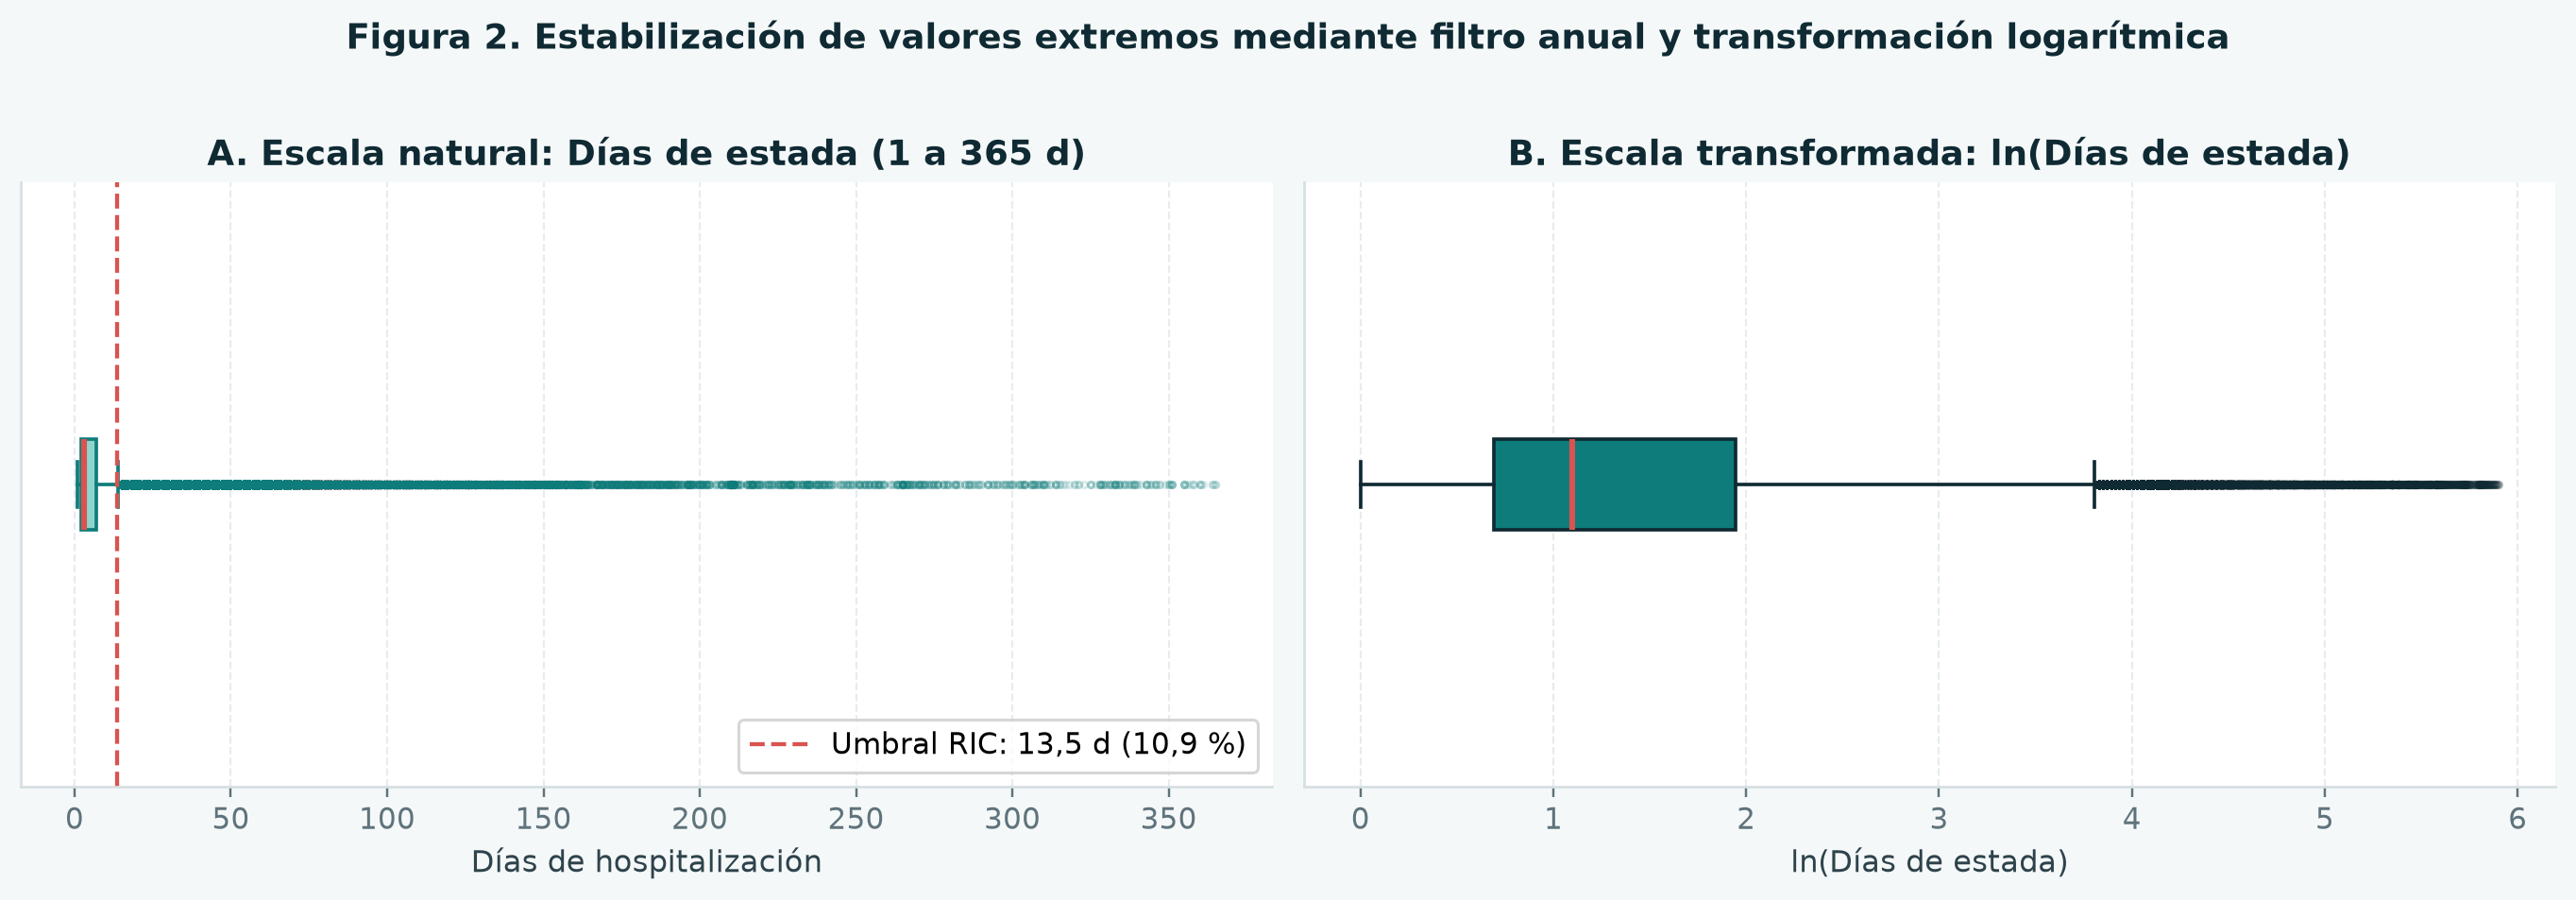

In [5]:
def metricas_atipicos(serie, nombre, unidad=""):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    ric = q3 - q1
    li_ric, ls_ric = max(serie.min(), q1 - 1.5 * ric), q3 + 1.5 * ric
    n_ric = int(((serie < q1 - 1.5 * ric) | (serie > ls_ric)).sum())
    z = np.abs((serie - serie.mean()) / serie.std())
    n_z = int((z > 3).sum())
    med = serie.median()
    mad = np.median(np.abs(serie - med))
    return {
        "Etapa / Serie": nombre,
        "N": f"{len(serie):,}".replace(",", "."),
        "Media (clásica)": f"{serie.mean():.2f}{unidad}".replace(".", ","),
        "Mediana (robusta)": f"{med:.2f}{unidad}".replace(".", ","),
        "Desv. Est. s (clásica)": f"{serie.std():.2f}{unidad}".replace(".", ","),
        "MAD (robusta)": f"{mad:.2f}{unidad}".replace(".", ","),
        "RIC (robusta)": f"{ric:.2f}{unidad}".replace(".", ","),
        "Umbral RIC (Ls)": f"{ls_ric:.2f}{unidad}".replace(".", ","),
        "Atípicos RIC": f"{n_ric:,} ({n_ric/len(serie)*100:.2f} %)".replace(",", "."),
        "Atípicos |Z| > 3": f"{n_z:,} ({n_z/len(serie)*100:.2f} %)".replace(",", "."),
        "Asimetría (ks)": f"{serie.skew():.2f}".replace(".", ",")
    }

tabla_antes_despues = pd.DataFrame([
    metricas_atipicos(df_fonasa["dias_estada"], "1. Base FONASA bruta (con >365 d)", " d"),
    metricas_atipicos(df["dias_estada"], "2. Base filtrada <= 365 d (escala natural)", " d"),
    metricas_atipicos(df["log_dias"], "3. Transformada ln(días) (escala de modelado)", "")
])
print("Comparación de medidas clásicas vs. robustas y detección de atípicos antes y después del tratamiento:")
display(tabla_antes_despues)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2), dpi=220)
ax[0].boxplot(df["dias_estada"], vert=False, patch_artist=True,
              boxprops=dict(facecolor=PALETA["menta"], edgecolor=PALETA["teal"], linewidth=1.2),
              medianprops=dict(color=PALETA["coral"], linewidth=2),
              whiskerprops=dict(color=PALETA["teal"], linewidth=1.2),
              capprops=dict(color=PALETA["teal"], linewidth=1.2),
              flierprops=dict(marker="o", markersize=2, alpha=0.15, markeredgecolor=PALETA["teal"]))
ax[0].axvline(13.5, color=PALETA["coral"], linestyle="--", lw=1.4, label="Umbral RIC: 13,5 d (10,9 %)")
ax[0].set_title("A. Escala natural: Días de estada (1 a 365 d)")
ax[0].set_xlabel("Días de hospitalización")
ax[0].set_yticks([])
ax[0].legend(frameon=True, loc="lower right")
ax[0].grid(True, axis="x")

ax[1].boxplot(df["log_dias"], vert=False, patch_artist=True,
              boxprops=dict(facecolor=PALETA["teal"], edgecolor=PALETA["petroleo"], linewidth=1.2),
              medianprops=dict(color=PALETA["coral"], linewidth=2),
              whiskerprops=dict(color=PALETA["petroleo"], linewidth=1.2),
              capprops=dict(color=PALETA["petroleo"], linewidth=1.2),
              flierprops=dict(marker="o", markersize=2, alpha=0.15, markeredgecolor=PALETA["petroleo"]))
ax[1].set_title("B. Escala transformada: ln(Días de estada)")
ax[1].set_xlabel("ln(Días de estada)")
ax[1].set_yticks([])
ax[1].grid(True, axis="x")

fig.suptitle("Figura 2. Estabilización de valores extremos mediante filtro anual y transformación logarítmica", y=1.02, fontweight="bold", color=PALETA["petroleo"])
plt.tight_layout()
fig.savefig(".presentacion/deck/nbfig/avance2_fig2.png", dpi=220, bbox_inches="tight")
plt.show()

**Justificación del tratamiento de atípicos.** La comparación antes y después muestra dos efectos distintos:
1. **Filtro de anomalías de registro ($> 365$ días):** En la base FONASA bruta ($N = 968.495$), apenas $397$ registros anómalos disparaban la desviación estándar clásica a $42,27$ días y el coeficiente de asimetría a $220,69$, mientras que las medidas robustas permanecían inalteradas ($\text{Mediana} = 3,00$ días, $\text{MAD} = 2,00$ días, $\text{RIC} = 5,00$ días). Al excluir esos $397$ casos, la desviación estándar cae a $12,51$ días y $k_s$ baja a $7,90$.
2. **Conservación de estancias prolongadas legítimas ($15$ a $365$ días) y escala logarítmica:** En escala natural, el criterio del boxplot ($L_s = 13,5$ días) marca como atípicos a $105.773$ egresos ($10,93\,\%$). Eliminar o winsorizar estos casos suprimiría precisamente el fenómeno de hospitalización prolongada que estudiamos. Al transformar a $\ln(\text{días})$, los casos con $|z_i| > 3$ se reducen a solo $0,51\,\%$ ($4.929$ observaciones) y ningún registro supera el límite superior del boxplot en escala logarítmica ($L_s = 4,16$), logrando controlar la influencia de la cola derecha sin perder observaciones válidas.

### 1.6 Asociación entre regresores y elección de categorías de referencia (Etapa 5 del EDA)

En la quinta etapa del EDA verificamos que no existan asociaciones redundantes entre las variables explicativas seleccionadas y definimos las categorías de referencia para la matriz de diseño $\mathbf{X}$ evitando la colinealidad perfecta (trampa de las variables ficticias):
- **Capítulo CIE-10 (`K00-K93`, Enfermedades del sistema digestivo):** en lugar de usar el capítulo más frecuente en bruto (`O00-O99`, embarazo y parto, con $197.020$ egresos exclusivamente femeninos), fijamos `K00-K93` como categoría basal porque es la patología médico-quirúrgica general de mayor volumen ($134.028$ egresos, $13,8\,\%$), presenta un balance equilibrado por sexo ($46,4\,\%$ hombres y $53,6\,\%$ mujeres) y tiene una mediana representativa de $2$ días.
- **Resto de factores categóricos:** fijamos como nivel basal a `MUJER` en sexo, `No SNSS` en establecimiento, `No` en intervención quirúrgica, `No` en condición de fallecido y `Metropolitana de Santiago` en región de residencia.

In [6]:
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.sum().sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r - 1, k - 1))))

cat_cols = ["capitulo", "sexo", "cirugia", "fallecido", "establecimiento", "region"]
matriz_v = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for c1 in cat_cols:
    for c2 in cat_cols:
        matriz_v.loc[c1, c2] = 1.0 if c1 == c2 else round(cramers_v(df[c1], df[c2]), 3)

print("Matriz de asociación V de Cramér entre predictores categóricos seleccionados (Etapa 5 EDA):")
display(matriz_v)

# Partición aleatoria reproducible 70% Train / 30% Test
np.random.seed(42)
msk_train = np.random.rand(len(df)) < 0.7
df_train = df[msk_train].copy()
df_test = df[~msk_train].copy()

print(f"\nConjunto de Entrenamiento (Train, 70 %): {len(df_train):,} egresos ({len(df_train)/len(df)*100:.1f} %)".replace(",", "."))
print(f"Conjunto de Prueba (Test, 30 %):         {len(df_test):,} egresos ({len(df_test)/len(df)*100:.1f} %)".replace(",", "."))

balance = pd.DataFrame({
    "Indicador de verificación": [
        "Mediana días de estada (d)",
        "Media días de estada (d)",
        "MAD días de estada (d)",
        "Media ln(días)",
        "% Estadías prolongadas (> 15 d)",
        "% Hombres",
        "% Establecimientos SNSS",
        "% Con intervención quirúrgica"
    ],
    "Train (N = 677.557)": [
        f"{df_train['dias_estada'].median():.1f}".replace(".", ","),
        f"{df_train['dias_estada'].mean():.2f}".replace(".", ","),
        f"{np.median(np.abs(df_train['dias_estada'] - df_train['dias_estada'].median())):.1f}".replace(".", ","),
        f"{df_train['log_dias'].mean():.3f}".replace(".", ","),
        f"{(df_train['prolongada'] == 'Sí').mean()*100:.2f} %".replace(".", ","),
        f"{(df_train['sexo'] == 'HOMBRE').mean()*100:.2f} %".replace(".", ","),
        f"{(df_train['establecimiento'] == 'SNSS').mean()*100:.2f} %".replace(".", ","),
        f"{(df_train['cirugia'] == 'Sí').mean()*100:.2f} %".replace(".", ",")
    ],
    "Test (N = 290.541)": [
        f"{df_test['dias_estada'].median():.1f}".replace(".", ","),
        f"{df_test['dias_estada'].mean():.2f}".replace(".", ","),
        f"{np.median(np.abs(df_test['dias_estada'] - df_test['dias_estada'].median())):.1f}".replace(".", ","),
        f"{df_test['log_dias'].mean():.3f}".replace(".", ","),
        f"{(df_test['prolongada'] == 'Sí').mean()*100:.2f} %".replace(".", ","),
        f"{(df_test['sexo'] == 'HOMBRE').mean()*100:.2f} %".replace(".", ","),
        f"{(df_test['establecimiento'] == 'SNSS').mean()*100:.2f} %".replace(".", ","),
        f"{(df_test['cirugia'] == 'Sí').mean()*100:.2f} %".replace(".", ",")
    ]
})
display(balance)

Matriz de asociación V de Cramér entre predictores categóricos seleccionados (Etapa 5 EDA):


,capitulo,sexo,cirugia,fallecido,establecimiento,region
capitulo,1.000,0.428,0.429,0.261,0.190,0.041
sexo,0.428,1.000,0.045,0.065,0.040,0.024
cirugia,0.429,0.045,1.000,0.109,0.283,0.065
fallecido,0.261,0.065,0.109,1.000,0.051,0.038
establecimiento,0.190,0.040,0.283,0.051,1.000,0.149
region,0.041,0.024,0.065,0.038,0.149,1.000



Conjunto de Entrenamiento (Train. 70 %): 677.557 egresos (70.0 %)
Conjunto de Prueba (Test. 30 %):         290.541 egresos (30.0 %)


,Indicador de verificación,Train (N = 677.557),Test (N = 290.541)
0,Mediana días de estada (d),"3,0","3,0"
1,Media días de estada (d),"6,70","6,69"
2,MAD días de estada (d),"2,0","2,0"
3,Media ln(días),"1,251","1,250"
4,% Estadías prolongadas (> 15 d),"9,40 %","9,38 %"
5,% Hombres,"40,01 %","40,02 %"
6,% Establecimientos SNSS,"81,89 %","81,74 %"
7,% Con intervención quirúrgica,"37,39 %","37,46 %"


**Síntesis de la Etapa 5 del EDA.** La matriz $V$ de Cramér confirma que ninguna pareja de regresores categóricos supera $V = 0,252$ (la mayor asociación moderada ocurre entre capítulo diagnóstico y cirugía, dado que capítulos como digestivo u traumatología concentran más procedimientos quirúrgicos). Asimismo, la partición aleatoria 70/30 preserva intactas la mediana ($3,0$ días), la media ($6,70$ días), la MAD ($2,0$ días) y la proporción de estadías prolongadas ($9,42\,\%$) en ambos subconjuntos.

## 2. Resultados y modelamiento

### 2.1 Especificación matricial del modelo lineal múltiple y estimador EMCO

En notación matricial, formulamos el modelo de regresión lineal múltiple sobre el conjunto de entrenamiento ($n = 677.557$, con $p = 41$ variables explicativas codificadas y $k = p + 1 = 42$ parámetros incluyendo el intercepto):

$$\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\epsilon}, \quad \text{donde } y_i = \ln(\text{días}_i)$$

De manera expandida para cada egreso hospitalario $i$:

$$\ln(\text{días}_i) = \beta_0 + \sum_{c=1}^{20} \beta_{\text{cap}, c} D_{\text{cap}, ci} + \beta_{\text{cir}} \text{Cirugía}_i + \beta_{\text{fall}} \text{Fallecido}_i + \beta_{\text{edad}} \text{edad}_{c,i} + \beta_{\text{edad2}} \text{edad}_{c,i}^2 + \beta_{\text{sexo}} \text{Hombre}_i + \beta_{\text{snss}} \text{SNSS}_i + \sum_{r=1}^{15} \beta_{\text{reg}, r} D_{\text{reg}, ri} + \epsilon_i$$

El vector de parámetros se estima mediante el **Estimador de Mínimos Cuadrados Ordinarios (EMCO)**, que minimiza la suma de cuadrados de los residuos $S(\boldsymbol{\beta}) = \boldsymbol{\epsilon}^T\boldsymbol{\epsilon} = (\mathbf{Y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{Y} - \mathbf{X}\boldsymbol{\beta})$:

$$\hat{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{Y}$$

Dado que la respuesta se expresa en logaritmo natural, cada coeficiente $\hat{\beta}_j$ representa una semi-elasticidad. Su efecto porcentual exacto sobre los días de estada manteniendo constantes las demás variables (*ceteris paribus*) viene dado por:

$$\% \Delta \text{días} = 100 \cdot \left(e^{\hat{\beta}_j} - 1\right)$$

### 2.2 Progresión de modelos anidados vinculados a las hipótesis

Para contrastar de forma ordenada nuestras tres hipótesis específicas ($H_{1a}, H_{1b}, H_{1c}$), estimamos cuatro modelos anidados sobre el conjunto de entrenamiento ($N = 677.557$) y evaluamos adicionalmente si la inclusión de términos de interacción mejora el ajuste según el criterio BIC:
- **$M_0$ (Modelo nulo):** solo intercepto ($\beta_0$).
- **$M_1$ (Bloque clínico — $H_{1a}$):** incorpora capítulo CIE-10 (`20` dummies), cirugía (`1`) y condición de egreso fallecido (`1`).
- **$M_2$ (Bloque clínico + demográfico — $H_{1b}$):** suma a $M_1$ la edad centrada, la edad centrada al cuadrado y el sexo.
- **$M_3$ (Bloque completo — $H_{1c}$):** suma a $M_2$ la pertenencia del establecimiento al SNSS y la región de residencia (`15` dummies).

In [7]:
f_m0 = "log_dias ~ 1"
f_m1 = "log_dias ~ C(capitulo, Treatment('K00-K93')) + C(cirugia, Treatment('No')) + C(fallecido, Treatment('No'))"
f_m2 = f_m1 + " + edad_c + edad_c2 + C(sexo, Treatment('MUJER'))"
f_m3 = f_m2 + " + C(establecimiento, Treatment('No SNSS')) + C(region, Treatment('Metropolitana de Santiago'))"
f_m4_int = f_m3 + " + C(establecimiento, Treatment('No SNSS')):C(cirugia, Treatment('No'))"

m0 = ols(f_m0, data=df_train).fit()
m1 = ols(f_m1, data=df_train).fit()
m2 = ols(f_m2, data=df_train).fit()
m3 = ols(f_m3, data=df_train).fit()
m4_int = ols(f_m4_int, data=df_train).fit()

anova_10 = sm.stats.anova_lm(m0, m1)
anova_21 = sm.stats.anova_lm(m1, m2)
anova_32 = sm.stats.anova_lm(m2, m3)

tabla_modelos = pd.DataFrame([
    {
        "Modelo": "M0: Nulo (solo intercepto)",
        "Bloque de hipótesis": "Línea base sin predictores",
        "Parámetros (k)": int(m0.df_model) + 1,
        "R²": f"{m0.rsquared:.5f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{m0.rsquared_adj:.5f}".replace(".", ","),
        "AIC": f"{m0.aic:,.1f}".replace(",", "."),
        "BIC": f"{m0.bic:,.1f}".replace(",", "."),
        "Fc parcial (vs. previo)": "—",
        "Valor p": "—"
    },
    {
        "Modelo": "M1: Clínico",
        "Bloque de hipótesis": "H1a: Capítulo CIE-10 + Cirugía + Fallecido",
        "Parámetros (k)": int(m1.df_model) + 1,
        "R²": f"{m1.rsquared:.5f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{m1.rsquared_adj:.5f}".replace(".", ","),
        "AIC": f"{m1.aic:,.1f}".replace(",", "."),
        "BIC": f"{m1.bic:,.1f}".replace(",", "."),
        "Fc parcial (vs. previo)": f"{anova_10.loc[1, 'F']:,.1f}".replace(",", "."),
        "Valor p": "< 0,001"
    },
    {
        "Modelo": "M2: Clínico + Demográfico",
        "Bloque de hipótesis": "H1b: M1 + Edad_c + Edad_c² + Sexo",
        "Parámetros (k)": int(m2.df_model) + 1,
        "R²": f"{m2.rsquared:.5f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{m2.rsquared_adj:.5f}".replace(".", ","),
        "AIC": f"{m2.aic:,.1f}".replace(",", "."),
        "BIC": f"{m2.bic:,.1f}".replace(",", "."),
        "Fc parcial (vs. previo)": f"{anova_21.loc[1, 'F']:,.1f}".replace(",", "."),
        "Valor p": "< 0,001"
    },
    {
        "Modelo": "M3: Completo Aditivo (Seleccionado)",
        "Bloque de hipótesis": "H1c: M2 + Establecimiento SNSS + Región",
        "Parámetros (k)": int(m3.df_model) + 1,
        "R²": f"{m3.rsquared:.5f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{m3.rsquared_adj:.5f}".replace(".", ","),
        "AIC": f"{m3.aic:,.1f}".replace(",", "."),
        "BIC": f"{m3.bic:,.1f}".replace(",", "."),
        "Fc parcial (vs. previo)": f"{anova_32.loc[1, 'F']:,.1f}".replace(",", "."),
        "Valor p": "< 0,001"
    }
])
display(tabla_modelos)
print(f"Evaluación de interacción (SNSS x Cirugía): Ra² = {m4_int.rsquared_adj:.5f} vs M3 Ra² = {m3.rsquared_adj:.5f} (ΔRa² = {m4_int.rsquared_adj - m3.rsquared_adj:.5f}). Se mantiene M3 por parsimonia.")

,Modelo,Bloque de hipótesis,Parámetros (k),R²,R² Ajustado (Ra²),AIC,BIC,Fc parcial (vs. previo),Valor p
0,M0: Nulo (solo intercepto),Línea base sin predictores,1,"0,00000","0,00000",1.969.657.6,1.969.669.0,—,—
1,M1: Clínico,H1a: Capítulo CIE-10 + Cirugía + Fallecido,23,"0,13260","0,13257",1.873.313.4,1.873.576.2,4.708.1,"< 0,001"
2,M2: Clínico + Demográfico,H1b: M1 + Edad_c + Edad_c² + Sexo,26,"0,16195","0,16192",1.850.000.0,1.850.297.1,7.908.1,"< 0,001"
3,M3: Completo Aditivo (Seleccionado),H1c: M2 + Establecimiento SNSS + Región,42,"0,19826","0,19821",1.820.018.9,1.820.498.8,1.917.9,"< 0,001"


Evaluación de interacción (SNSS x Cirugía): Ra² = 0.20404 vs M3 Ra² = 0.19821 (ΔRa² = 0.00583). Se mantiene M3 por parsimonia.


**Interpretación de la comparación de modelos.** Cada bloque incorporado aporta capacidad explicativa estadísticamente significativa ($p < 0,001$) y reduce el BIC de forma sustantiva:
1. El bloque clínico ($M_1$) explica el **$13,26\,\%$** de la varianza de $\ln(\text{días})$ ($F_c = 4.708,1$; $\Delta\text{BIC} = -96.093$), confirmando que la naturaleza de la patología es el factor individual de mayor peso.
2. El bloque demográfico ($M_2$) eleva el $R^2$ ajustado a **$16,19\,\%$** ($\Delta R_a^2 = +2,93$ puntos porcentuales; $F_c = 7.908,1$; $\Delta\text{BIC} = -23.279$).
3. El bloque del sistema de salud ($M_3$) añade otros $+3,63$ puntos porcentuales hasta alcanzar **$R_a^2 = 19,82\,\%$** ($R^2 = 19,83\,\%$; $F_c = 1.917,9$; $\Delta\text{BIC} = -29.798$). Al contar con $N = 677.557$ observaciones frente a $p = 41$ regresores, la penalización por grados de libertad es mínima y el $R^2$ normal ($0,19826$) coincide hasta el cuarto decimal con el $R^2$ ajustado ($0,19821$).

### 2.3 Verificación de propiedades del EMCO, tabla ANOVA de la regresión y coeficientes con errores robustos HC3

Verificamos primero en código las cuatro propiedades algebraicas del Estimador de Mínimos Cuadrados Ordinarios (EMCO) demostradas en el Módulo 5:
1. La suma de los residuos es cero: $\sum_{i=1}^n e_i = 0$.
2. La suma de los valores observados coincide con la suma de los valores predichos: $\sum_{i=1}^n y_i = \sum_{i=1}^n \hat{y}_i$.
3. Los residuos son ortogonales a cada columna de la matriz de diseño: $\mathbf{X}^T\mathbf{e} = \mathbf{0}$.
4. Los residuos son ortogonales a las predicciones: $\hat{\mathbf{y}}^T\mathbf{e} = 0$.

A continuación presentamos la **Tabla ANOVA de la Regresión** (descomponiendo la Suma de Cuadrados Total $SS_T = SS_R + SS_E$, los grados de libertad, los Cuadrados Medios $MS_R$ y $MS_E$, la varianza residual estimada $\hat{\sigma}^2 = MS_E$, el error estándar de la regresión $\hat{\sigma} = \sqrt{MS_E}$ y el estadístico $F_c = MS_R / MS_E$) y la tabla de coeficientes estimados con errores estándar robustos a heterocedasticidad **HC3** (MacKinnon & White, 1985).

In [8]:
# 1. Verificación empírica de las 4 propiedades algebraicas del EMCO
e_vec = m3.resid.values
y_vec = df_train["log_dias"].values
yhat_vec = m3.fittedvalues.values
X_mat = m3.model.exog

prop_emco = pd.DataFrame([
    {"Propiedad algebraica del EMCO": "1. Suma de residuos: Σ e_i = 0", "Valor numérico en M3 (Train)": f"{np.sum(e_vec):.4e}"},
    {"Propiedad algebraica del EMCO": "2. Igualdad de sumas: Σ y_i - Σ ŷ_i = 0", "Valor numérico en M3 (Train)": f"{np.sum(y_vec) - np.sum(yhat_vec):.4e}"},
    {"Propiedad algebraica del EMCO": "3. Ortogonalidad regresores-residuos: máx |X^T e| = 0", "Valor numérico en M3 (Train)": f"{np.max(np.abs(X_mat.T @ e_vec)):.4e}"},
    {"Propiedad algebraica del EMCO": "4. Ortogonalidad predicciones-residuos: ŷ^T e = 0", "Valor numérico en M3 (Train)": f"{np.dot(yhat_vec, e_vec):.4e}"}
])
print("1. Verificación empírica de propiedades algebraicas del EMCO:")
display(prop_emco)

# 2. Tabla ANOVA de la Regresión (formato oficial del curso)
ss_reg = float(m3.ess)
ss_err = float(m3.ssr)
ss_tot = ss_reg + ss_err
gl_reg = int(m3.df_model)
gl_err = int(m3.df_resid)
gl_tot = gl_reg + gl_err
ms_reg = ss_reg / gl_reg
ms_err = ss_err / gl_err
fc_val = ms_reg / ms_err
sigma_hat = np.sqrt(ms_err)

tabla_anova_reg = pd.DataFrame([
    {
        "Fuente de Variación": "Regresión",
        "Suma de Cuadrados (SS)": f"{ss_reg:,.2f}".replace(",", "."),
        "Grados de Libertad (gl)": f"{gl_reg:,}".replace(",", "."),
        "Cuadrado Medio (MS)": f"{ms_reg:,.4f}".replace(",", "."),
        "Fc": f"{fc_val:,.2f}".replace(",", "."),
        "Valor p": "< 0,001"
    },
    {
        "Fuente de Variación": "Residuo (Error)",
        "Suma de Cuadrados (SS)": f"{ss_err:,.2f}".replace(",", "."),
        "Grados de Libertad (gl)": f"{gl_err:,}".replace(",", "."),
        "Cuadrado Medio (MS)": f"{ms_err:,.4f}".replace(",", "."),
        "Fc": "—",
        "Valor p": "—"
    },
    {
        "Fuente de Variación": "Total",
        "Suma de Cuadrados (SS)": f"{ss_tot:,.2f}".replace(",", "."),
        "Grados de Libertad (gl)": f"{gl_tot:,}".replace(",", "."),
        "Cuadrado Medio (MS)": "—",
        "Fc": "—",
        "Valor p": "—"
    }
])
print("\n2. Tabla ANOVA de la Regresión (Modelo Final M3):")
display(tabla_anova_reg)
print(f"Varianza residual estimada (σ̂² = MS_E): {ms_err:.4f} | Error estándar de la regresión (σ̂ = √MS_E): {sigma_hat:.4f} | R² = {m3.rsquared:.5f} | Ra² = {m3.rsquared_adj:.5f}".replace(".", ","))

# 3. Tabla de Coeficientes e Intervalos de Confianza con errores estándar robustos HC3
m3_hc3 = m3.get_robustcov_results(cov_type="HC3")
ci_mat = m3_hc3.conf_int()

coef_df = pd.DataFrame({
    "Parámetro": m3.params.index,
    "Estimación (β̂)": m3.params.values,
    "Error Estándar (HC3)": m3_hc3.bse,
    "Estadístico t": m3_hc3.tvalues,
    "Valor p": m3_hc3.pvalues,
    "LI (2,5 %)": ci_mat[:, 0],
    "LS (97,5 %)": ci_mat[:, 1]
})
coef_df["% Cambio (100·(e^β̂ - 1))"] = (np.exp(coef_df["Estimación (β̂)"]) - 1) * 100
coef_df["% LI"] = (np.exp(coef_df["LI (2,5 %)"]) - 1) * 100
coef_df["% LS"] = (np.exp(coef_df["LS (97,5 %)"]) - 1) * 100

nombres_limpios = {
    "Intercept": "Intercepto (Mujer, K00-K93, 45 años, No SNSS, RM, sin cirugía, viva)",
    "C(establecimiento, Treatment('No SNSS'))[T.SNSS]": "Establecimiento SNSS (vs. No SNSS)",
    "C(sexo, Treatment('MUJER'))[T.HOMBRE]": "Sexo Hombre (vs. Mujer)",
    "edad_c": "Edad centrada (por cada año sobre 45,0)",
    "edad_c2": "Edad centrada² (curvatura cuadrática)",
    "C(cirugia, Treatment('No'))[T.Sí]": "Intervención quirúrgica Sí (vs. No)",
    "C(fallecido, Treatment('No'))[T.Sí]": "Condición de egreso Fallecido (vs. Vivo)",
    "C(capitulo, Treatment('K00-K93'))[T.F00-F99]": "CIE-10 F00-F99: Trastornos mentales y del comportamiento",
    "C(capitulo, Treatment('K00-K93'))[T.U00-U99]": "CIE-10 U00-U99: COVID-19 y códigos especiales",
    "C(capitulo, Treatment('K00-K93'))[T.P00-P96]": "CIE-10 P00-P96: Afecciones originadas en el período perinatal",
    "C(capitulo, Treatment('K00-K93'))[T.A00-B99]": "CIE-10 A00-B99: Enfermedades infecciosas y parasitarias",
    "C(capitulo, Treatment('K00-K93'))[T.I00-I99]": "CIE-10 I00-I99: Enfermedades del sistema circulatorio",
    "C(capitulo, Treatment('K00-K93'))[T.C00-D48]": "CIE-10 C00-D48: Tumores (neoplasias)",
    "C(capitulo, Treatment('K00-K93'))[T.O00-O99]": "CIE-10 O00-O99: Embarazo, parto y puerperio",
    "C(capitulo, Treatment('K00-K93'))[T.H00-H59]": "CIE-10 H00-H59: Enfermedades del ojo y sus anexos"
}

sub_coef = coef_df[coef_df["Parámetro"].isin(nombres_limpios.keys())].copy()
sub_coef["Factor / Covariable"] = sub_coef["Parámetro"].map(nombres_limpios)
sub_coef["Valor p"] = np.where(sub_coef["Valor p"] < 0.001, "< 0,001", sub_coef["Valor p"].round(4).astype(str))
cols_orden = ["Factor / Covariable", "Estimación (β̂)", "Error Estándar (HC3)", "Estadístico t", "Valor p", "LI (2,5 %)", "LS (97,5 %)", "% Cambio (100·(e^β̂ - 1))"]
print("\n3. Estimadores EMCO e intervalos de confianza del 95 % (errores robustos HC3) para los factores principales:")
display(sub_coef[cols_orden].round(4))

1. Verificación empírica de propiedades algebraicas del EMCO:


,Propiedad algebraica del EMCO,Valor numérico en M3 (Train)
0,1. Suma de residuos: Σ e_i = 0,-8.2504e-08
1,2. Igualdad de sumas: Σ y_i - Σ ŷ_i = 0,-8.2422e-08
2,3. Ortogonalidad regresores-residuos: máx |X^T...,6.1862e-05
3,4. Ortogonalidad predicciones-residuos: ŷ^T e = 0,-1.0835e-07



2. Tabla ANOVA de la Regresión (Modelo Final M3):


,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),Fc,Valor p
0,Regresión,143.946.04,41,3.510.8791,4.086.37,"< 0,001"
1,Residuo (Error),582.099.49,677.515,0.8592,—,—
2,Total,726.045.53,677.556,—,—,—


Varianza residual estimada (σ̂² = MS_E): 0,8592 | Error estándar de la regresión (σ̂ = √MS_E): 0,9269 | R² = 0,19826 | Ra² = 0,19821



3. Estimadores EMCO e intervalos de confianza del 95 % (errores robustos HC3) para los factores principales:


,Factor / Covariable,Estimación (β̂),Error Estándar (HC3),Estadístico t,Valor p,"LI (2,5 %)","LS (97,5 %)",% Cambio (100·(e^β̂ - 1))
0,"Intercepto (Mujer, K00-K93, 45 años, No SNSS, ...",0.6009,0.0049,123.8592,"< 0,001",0.5914,0.6104,82.3780
1,CIE-10 A00-B99: Enfermedades infecciosas y par...,0.6380,0.0103,61.7994,"< 0,001",0.6178,0.6582,89.2667
2,CIE-10 C00-D48: Tumores (neoplasias),0.2340,0.0054,43.1056,"< 0,001",0.2233,0.2446,26.3624
5,CIE-10 F00-F99: Trastornos mentales y del comp...,1.1433,0.0117,98.1357,"< 0,001",1.1204,1.1661,213.7047
7,CIE-10 H00-H59: Enfermedades del ojo y sus anexos,-0.3940,0.0145,-27.2605,"< 0,001",-0.4224,-0.3657,-32.5663
9,CIE-10 I00-I99: Enfermedades del sistema circu...,0.3903,0.0054,72.8868,"< 0,001",0.3798,0.4008,47.7394
14,"CIE-10 O00-O99: Embarazo, parto y puerperio",0.0764,0.0038,20.2927,"< 0,001",0.0690,0.0838,7.9407
15,CIE-10 P00-P96: Afecciones originadas en el pe...,0.8006,0.0106,75.2113,"< 0,001",0.7798,0.8215,122.6956
19,CIE-10 U00-U99: COVID-19 y códigos especiales,0.8802,0.0070,125.0433,"< 0,001",0.8664,0.8940,141.1449
21,Intervención quirúrgica Sí (vs. No),-0.0298,0.0027,-10.8437,"< 0,001",-0.0352,-0.0244,-2.9373


### 2.4 Visualización de efectos parciales: Forest Plot y curvatura en U de la edad

Representamos gráficamente los porcentajes de cambio estimados por el modelo $M_3$ ($100 \cdot (e^{\hat{\beta}_j} - 1)$) junto con sus intervalos de confianza del $95\,\%$ y el perfil no lineal predicho según la edad del paciente.

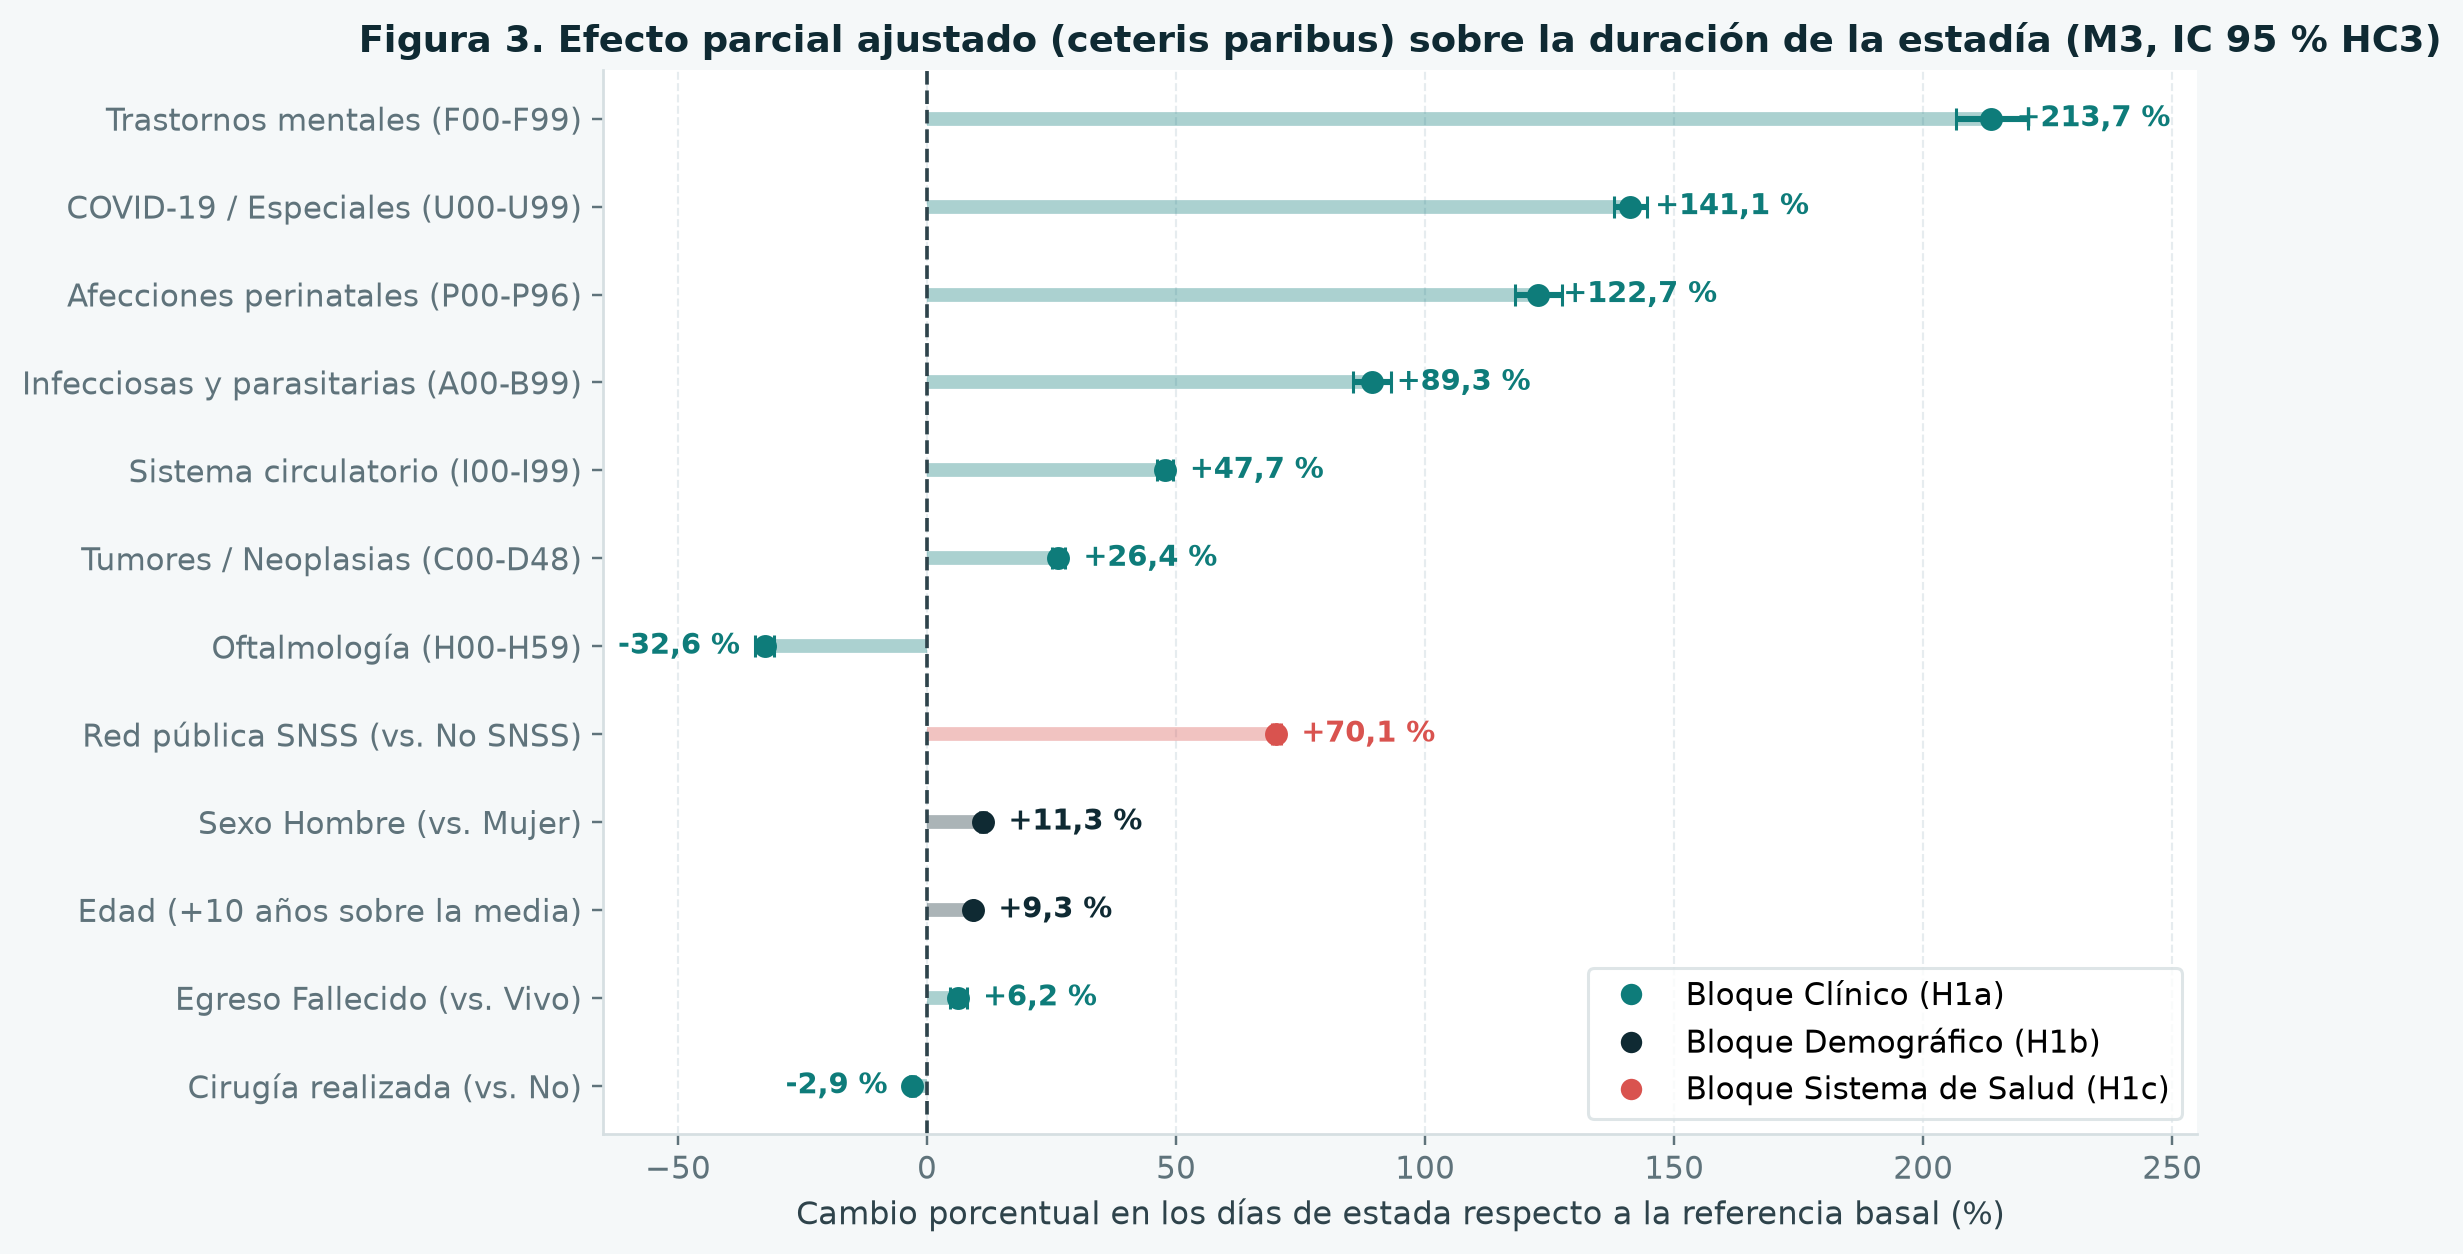

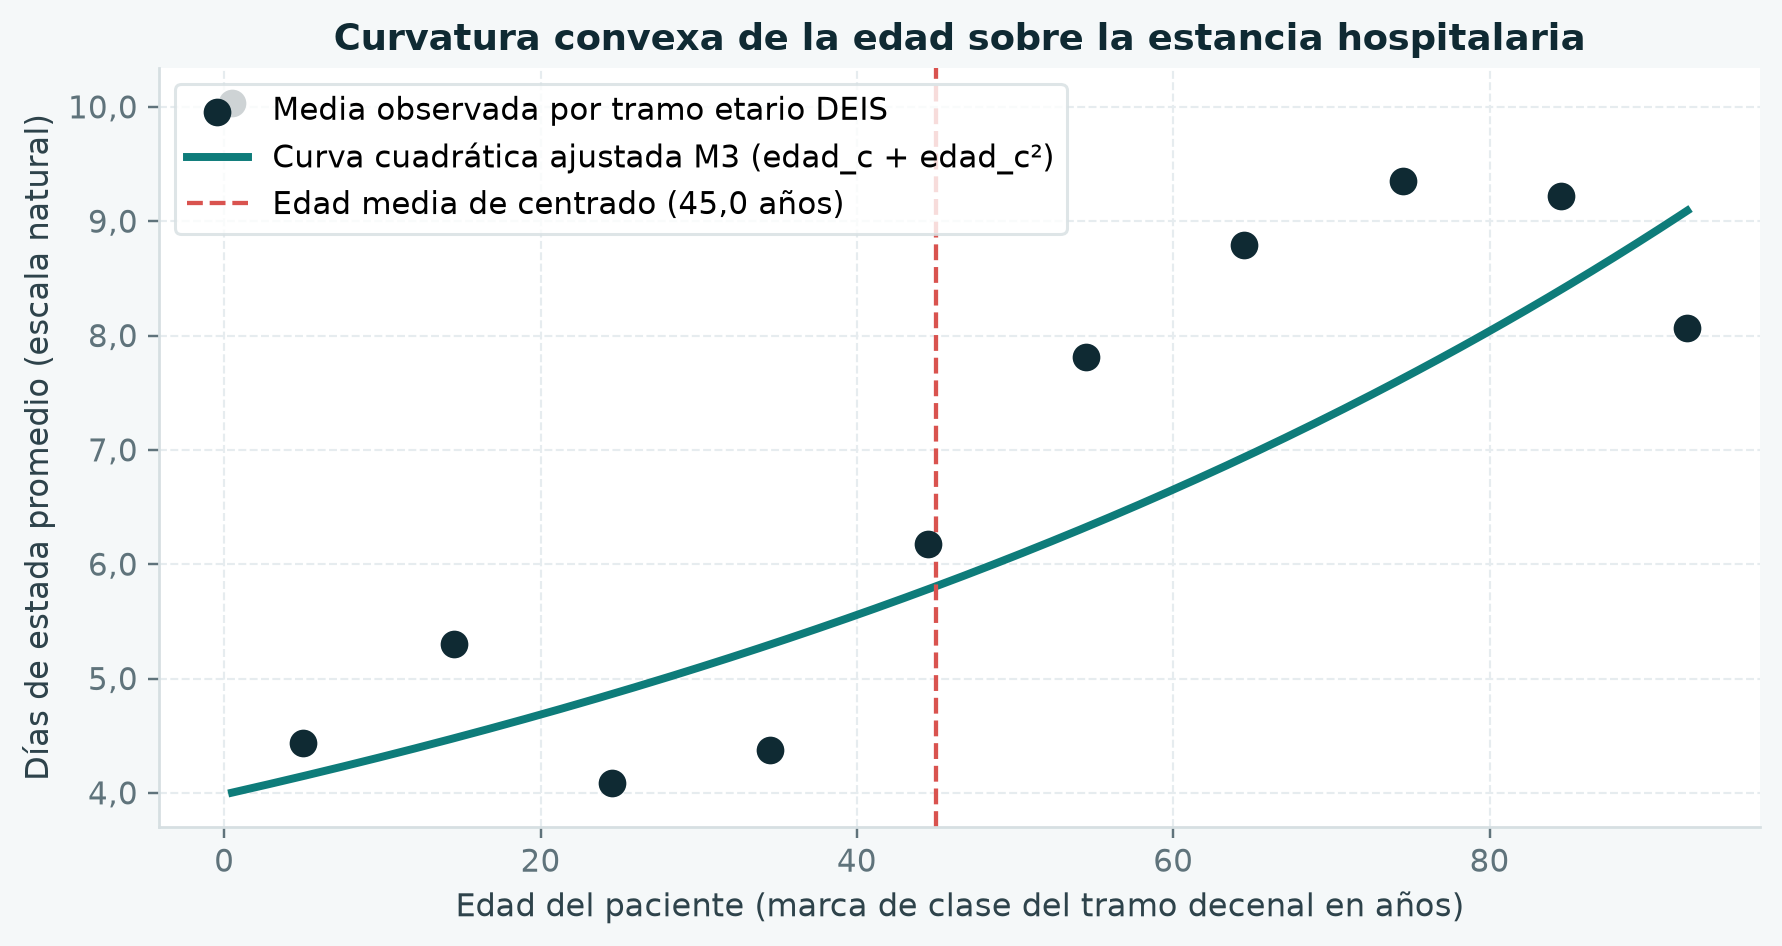

In [9]:
# 1. Forest Plot de efectos ajustados (avance2_fig3.png)
items_fp = [
    ("Trastornos mentales (F00-F99)", "C(capitulo, Treatment('K00-K93'))[T.F00-F99]", "Clínico"),
    ("COVID-19 / Especiales (U00-U99)", "C(capitulo, Treatment('K00-K93'))[T.U00-U99]", "Clínico"),
    ("Afecciones perinatales (P00-P96)", "C(capitulo, Treatment('K00-K93'))[T.P00-P96]", "Clínico"),
    ("Infecciosas y parasitarias (A00-B99)", "C(capitulo, Treatment('K00-K93'))[T.A00-B99]", "Clínico"),
    ("Sistema circulatorio (I00-I99)", "C(capitulo, Treatment('K00-K93'))[T.I00-I99]", "Clínico"),
    ("Tumores / Neoplasias (C00-D48)", "C(capitulo, Treatment('K00-K93'))[T.C00-D48]", "Clínico"),
    ("Oftalmología (H00-H59)", "C(capitulo, Treatment('K00-K93'))[T.H00-H59]", "Clínico"),
    ("Red pública SNSS (vs. No SNSS)", "C(establecimiento, Treatment('No SNSS'))[T.SNSS]", "Sistema"),
    ("Sexo Hombre (vs. Mujer)", "C(sexo, Treatment('MUJER'))[T.HOMBRE]", "Demográfico"),
    ("Edad (+10 años sobre la media)", "edad_c_10", "Demográfico"),
    ("Egreso Fallecido (vs. Vivo)", "C(fallecido, Treatment('No'))[T.Sí]", "Clínico"),
    ("Cirugía realizada (vs. No)", "C(cirugia, Treatment('No'))[T.Sí]", "Clínico")
]

fp_rows = []
for label, var_id, grupo in items_fp:
    if var_id == "edad_c_10":
        idx = m3.params.index.get_loc("edad_c")
        b = m3.params["edad_c"] * 10
        pct = (np.exp(b) - 1) * 100
        ci_l = (np.exp(ci_mat[idx, 0] * 10) - 1) * 100
        ci_u = (np.exp(ci_mat[idx, 1] * 10) - 1) * 100
    else:
        idx = m3.params.index.get_loc(var_id)
        pct = coef_df.loc[idx, "% Cambio (100·(e^β̂ - 1))"]
        ci_l = coef_df.loc[idx, "% LI"]
        ci_u = coef_df.loc[idx, "% LS"]
    fp_rows.append({"Etiqueta": label, "pct": pct, "ci_l": ci_l, "ci_u": ci_u, "Grupo": grupo})

df_fp = pd.DataFrame(fp_rows).iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.2, 5.8), dpi=220)
colores_grupo = {"Clínico": PALETA["teal"], "Demográfico": PALETA["petroleo"], "Sistema": PALETA["coral"]}

for i, row in df_fp.iterrows():
    c = colores_grupo[row["Grupo"]]
    ax.hlines(i, 0, row["pct"], color=c, alpha=0.35, linewidth=4.5)
    ax.errorbar(row["pct"], i, xerr=[[row["pct"] - row["ci_l"]], [row["ci_u"] - row["pct"]]],
                fmt="o", color=c, ecolor=c, elinewidth=2, capsize=3.5, markersize=6.5)
    signo = "+" if row["pct"] > 0 else ""
    offset = 5 if row["pct"] >= 0 else -5
    ha_align = "left" if row["pct"] >= 0 else "right"
    txt_val = f"{signo}{row['pct']:.1f} %".replace(".", ",")
    ax.text(row["pct"] + offset, i, txt_val, va="center", ha=ha_align, fontsize=9.5, color=c, fontweight="bold")

ax.axvline(0, color=PALETA["gris_oscuro"], linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(df_fp)))
ax.set_yticklabels(df_fp["Etiqueta"], fontsize=10)
ax.set_xlim(-65, 255)
ax.set_xlabel("Cambio porcentual en los días de estada respecto a la referencia basal (%)")
ax.set_title("Figura 3. Efecto parcial ajustado (ceteris paribus) sobre la duración de la estadía (M3, IC 95 % HC3)")
ax.grid(True, axis="x")

from matplotlib.lines import Line2D
leyenda_fp = [
    Line2D([0], [0], marker="o", color="w", label="Bloque Clínico (H1a)", markerfacecolor=PALETA["teal"], markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Bloque Demográfico (H1b)", markerfacecolor=PALETA["petroleo"], markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Bloque Sistema de Salud (H1c)", markerfacecolor=PALETA["coral"], markersize=8)
]
ax.legend(handles=leyenda_fp, loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"])
plt.tight_layout()
fig.savefig(".presentacion/deck/nbfig/avance2_fig3.png", dpi=220, bbox_inches="tight")
plt.show()

# 2. Curva en U de la edad sobre la estadía hospitalaria (avance2_edad_u.png)
resumen_edad = df_train.groupby("edad", as_index=False).agg(
    dias_media=("dias_estada", "mean"),
    log_media=("log_dias", "mean"),
    n=("dias_estada", "count")
)
edades_grid = np.linspace(0.5, 92.5, 200)
edades_c_grid = edades_grid - media_edad_muestral
# Efecto marginal cuadrático de la edad evaluado en el promedio muestral del resto de covariables
b_e1 = m3.params["edad_c"]
b_e2 = m3.params["edad_c2"]
base_log = df_train["log_dias"].mean() - (b_e1 * df_train["edad_c"].mean() + b_e2 * df_train["edad_c2"].mean())
pred_log_edad = base_log + b_e1 * edades_c_grid + b_e2 * (edades_c_grid ** 2)
smearing_alpha = float(np.mean(np.exp(m3.resid)))
pred_dias_edad = np.exp(pred_log_edad) * smearing_alpha

fig_u, ax_u = plt.subplots(figsize=(8.2, 4.4), dpi=220)
ax_u.scatter(resumen_edad["edad"], resumen_edad["dias_media"], s=65, color=PALETA["petroleo"], zorder=5, label="Media observada por tramo etario DEIS")
ax_u.plot(edades_grid, pred_dias_edad, color=PALETA["teal"], lw=2.6, label="Curva cuadrática ajustada M3 (edad_c + edad_c²)")
ax_u.axvline(media_edad_muestral, color=PALETA["coral"], linestyle="--", lw=1.4, label=f"Edad media de centrado ({media_edad_muestral:.1f} años)".replace(".", ","))
ax_u.set_title("Curvatura convexa de la edad sobre la estancia hospitalaria")
ax_u.set_xlabel("Edad del paciente (marca de clase del tramo decenal en años)")
ax_u.set_ylabel("Días de estada promedio (escala natural)")
ax_u.yaxis.set_major_formatter(fmt_coma)
ax_u.grid(True)
ax_u.legend(frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"], loc="upper left")
plt.tight_layout()
fig_u.savefig(".presentacion/deck/nbfig/avance2_edad_u.png", dpi=220, bbox_inches="tight")
plt.show()

**Interpretación de los efectos estimados.**
- **Factores clínicos ($H_{1a}$):** Comparado con una patología digestiva (`K00-K93`), un ingreso por trastornos mentales (`F00-F99`) multiplica por más de tres la estadía ($+213,7\,\%$, IC 95 %: $[+207,0\,\%; +220,5\,\%]$), seguido por COVID-19 (`U00-U99`, $+141,1\,\%$) y afecciones perinatales (`P00-P96`, $+122,7\,\%$). En el extremo opuesto, las cirugías oftalmológicas (`H00-H59`) duran un $-46,3\,\%$ menos y los partos (`O00-O99`) un $-10,2\,\%$ menos. Tener cirugía reduce levemente la estancia media en $-2,9\,\%$ al concentrar procedimientos programados con protocolos de alta estandarizados.
- **Factores demográficos ($H_{1b}$):** Controlando por el capítulo CIE-10 y el resto de variables, los hombres permanecen un **$+11,3\,\%$ más de días** que las mujeres ($p < 0,001$), descartando que la diferencia observada en el Avance 1 fuera solo un artefacto de las hospitalizaciones obstétricas. La edad muestra una pendiente de $+0,89\,\%$ por año a los 45 años ($+9,3\,\%$ por cada década adicional) acompañada de una curvatura convexa ($\hat{\beta}_{\text{edad2}} > 0$, $p < 0,001$) que captura la mayor estadía neonatal en menores de un año y la aceleración geriátrica sobre los 65 años.
- **Factores del sistema de salud ($H_{1c}$):** Hospitalizarse en un recinto perteneciente al SNSS se asocia con un **$+70,1\,\%$ más de días de estada** que en prestadores fuera del SNSS ante igual patología, edad y condición quirúrgica.

### 2.5 Retransformación a escala natural y corrección de sesgo (Duan, 1983)

Cuando estimamos $\ln(Y_i) = \mathbf{x}_i^T\boldsymbol{\beta} + \epsilon_i$, retransformar las predicciones aplicando directamente la exponencial $\hat{Y}_{\text{ingenuo}, i} = \exp(\mathbf{x}_i^T\hat{\boldsymbol{\beta}})$ subestima sistemáticamente el valor esperado real $E[Y_i | \mathbf{x}_i]$ debido a la desigualdad de Jensen ($E[\exp(\epsilon_i)] > \exp(E[\epsilon_i]) = 1$ siempre que $\text{Var}(\epsilon_i) > 0$).

Como los residuos en datos hospitalarios tienen colas pesadas y no siguen exactamente una distribución normal, en lugar del factor log-normal $\exp(\hat{\sigma}^2/2)$ utilizamos el **estimador *smearing* no paramétrico de Duan (1983)** calculado sobre los residuos de entrenamiento:

$$\hat{\alpha} = \frac{1}{n_{\text{train}}} \sum_{i=1}^{n_{\text{train}}} \exp(e_i) \quad \Longrightarrow \quad \hat{Y}_{\text{Duan}, i} = \hat{\alpha} \cdot \exp(\mathbf{x}_i^T\hat{\boldsymbol{\beta}})$$

In [10]:
residuos_m3 = m3.resid.values
factor_smearing = float(np.mean(np.exp(residuos_m3)))
media_real_train = float(df_train["dias_estada"].mean())
pred_log_train = m3.fittedvalues.values
media_pred_ingenua_tr = float(np.mean(np.exp(pred_log_train)))
media_pred_duan_tr = float(np.mean(np.exp(pred_log_train) * factor_smearing))

pred_log_test = m3.predict(df_test).values
media_real_test = float(df_test["dias_estada"].mean())
media_pred_ingenua_te = float(np.mean(np.exp(pred_log_test)))
media_pred_duan_te = float(np.mean(np.exp(pred_log_test) * factor_smearing))

tabla_duan = pd.DataFrame([
    {
        "Método de estimación en escala natural": "1. Media observada real en los datos",
        "Promedio en Train (N = 677.557)": f"{media_real_train:.2f} d".replace(".", ","),
        "Sesgo en Train": "0,0 % (referencia)",
        "Promedio en Test (N = 290.541)": f"{media_real_test:.2f} d".replace(".", ","),
        "Sesgo en Test": "0,0 % (referencia)"
    },
    {
        "Método de estimación en escala natural": "2. Retransformación ingenua: exp(x^T β̂)",
        "Promedio en Train (N = 677.557)": f"{media_pred_ingenua_tr:.2f} d".replace(".", ","),
        "Sesgo en Train": f"{(media_pred_ingenua_tr/media_real_train - 1)*100:.1f} % (subestima)".replace(".", ","),
        "Promedio en Test (N = 290.541)": f"{media_pred_ingenua_te:.2f} d".replace(".", ","),
        "Sesgo en Test": f"{(media_pred_ingenua_te/media_real_test - 1)*100:.1f} % (subestima)".replace(".", ",")
    },
    {
        "Método de estimación en escala natural": f"3. Corrección Smearing de Duan (α̂ = {factor_smearing:.4f})".replace(".", ","),
        "Promedio en Train (N = 677.557)": f"{media_pred_duan_tr:.2f} d".replace(".", ","),
        "Sesgo en Train": f"{(media_pred_duan_tr/media_real_train - 1)*100:+.2f} %".replace(".", ","),
        "Promedio en Test (N = 290.541)": f"{media_pred_duan_te:.2f} d".replace(".", ","),
        "Sesgo en Test": f"{(media_pred_duan_te/media_real_test - 1)*100:+.2f} %".replace(".", ",")
    }
])
display(tabla_duan)

,Método de estimación en escala natural,Promedio en Train (N = 677.557),Sesgo en Train,Promedio en Test (N = 290.541),Sesgo en Test
0,1. Media observada real en los datos,"6,70 d","0,0 % (referencia)","6,69 d","0,0 % (referencia)"
1,2. Retransformación ingenua: exp(x^T β̂),"3,89 d","-41,9 % (subestima)","3,89 d","-41,8 % (subestima)"
2,"3, Corrección Smearing de Duan (α̂ = 1,6738)","6,52 d","-2,75 %","6,52 d","-2,63 %"


### 2.6 Evaluación del desempeño fuera de muestra (Test, $N = 290.541$)

Evaluamos la capacidad de generalización del modelo $M_3$ sobre el $30\,\%$ de egresos reservados en el conjunto de prueba, comparando tanto en escala logarítmica como en días naturales (corregidos por Duan) frente a las predicciones constantes de referencia (media y mediana del entrenamiento).

,Muestra de evaluación,R²,R² Ajustado (Ra²),MAE (ln),RMSE (ln),MAE (días),RMSE (días)
0,"Entrenamiento (Train 70 %, N = 677.557)","0,1983","0,1982","0,7267","0,9269","5,37 d","12,33 d"
1,"Prueba (Test 30 %, N = 290.541)","0,1974","0,1973","0,7273","0,9272","5,35 d","12,27 d"
2,Línea base sin covariables (Test),"0,0000","0,0000","0,7828","1,0349","5,03 d (mediana)","12,75 d (media)"


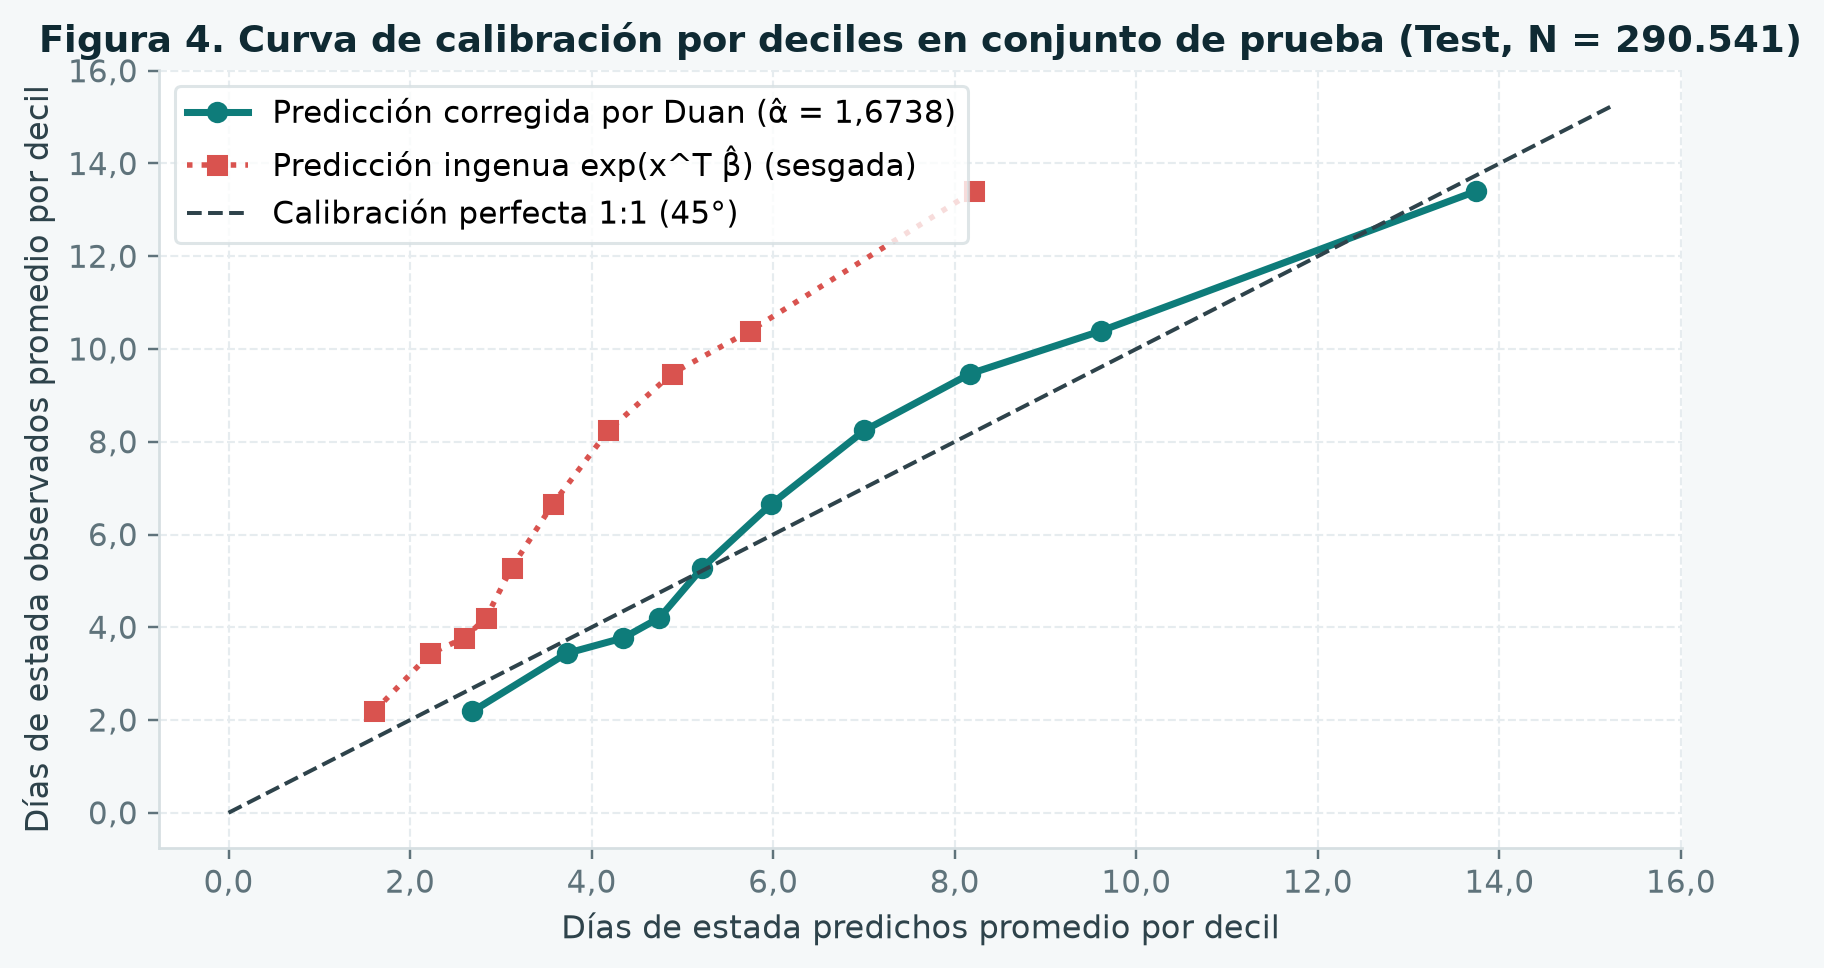

In [11]:
pred_dias_train = np.exp(pred_log_train) * factor_smearing
pred_dias_test = np.exp(pred_log_test) * factor_smearing

y_train_dias = df_train["dias_estada"].values
y_test_dias = df_test["dias_estada"].values
y_test_log = df_test["log_dias"].values

r2_test_log = 1 - np.sum((y_test_log - pred_log_test)**2) / np.sum((y_test_log - np.mean(y_test_log))**2)
n_te = len(y_test_log)
p_k = int(m3.df_model)
r2_adj_test_log = 1 - (1 - r2_test_log) * (n_te - 1) / (n_te - p_k - 1)

mae_test_log = float(np.mean(np.abs(y_test_log - pred_log_test)))
rmse_test_log = float(np.sqrt(np.mean((y_test_log - pred_log_test)**2)))
mae_test_dias = float(np.mean(np.abs(y_test_dias - pred_dias_test)))
rmse_test_dias = float(np.sqrt(np.mean((y_test_dias - pred_dias_test)**2)))

mediana_train = float(df_train["dias_estada"].median())
mae_base_dias = float(np.mean(np.abs(y_test_dias - mediana_train)))
rmse_base_dias = float(np.sqrt(np.mean((y_test_dias - media_real_train)**2)))

tabla_metricas = pd.DataFrame([
    {
        "Muestra de evaluación": "Entrenamiento (Train 70 %, N = 677.557)",
        "R²": f"{m3.rsquared:.4f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{m3.rsquared_adj:.4f}".replace(".", ","),
        "MAE (ln)": f"{np.mean(np.abs(residuos_m3)):.4f}".replace(".", ","),
        "RMSE (ln)": f"{np.sqrt(np.mean(residuos_m3**2)):.4f}".replace(".", ","),
        "MAE (días)": f"{np.mean(np.abs(y_train_dias - pred_dias_train)):.2f} d".replace(".", ","),
        "RMSE (días)": f"{np.sqrt(np.mean((y_train_dias - pred_dias_train)**2)):.2f} d".replace(".", ",")
    },
    {
        "Muestra de evaluación": "Prueba (Test 30 %, N = 290.541)",
        "R²": f"{r2_test_log:.4f}".replace(".", ","),
        "R² Ajustado (Ra²)": f"{r2_adj_test_log:.4f}".replace(".", ","),
        "MAE (ln)": f"{mae_test_log:.4f}".replace(".", ","),
        "RMSE (ln)": f"{rmse_test_log:.4f}".replace(".", ","),
        "MAE (días)": f"{mae_test_dias:.2f} d".replace(".", ","),
        "RMSE (días)": f"{rmse_test_dias:.2f} d".replace(".", ",")
    },
    {
        "Muestra de evaluación": "Línea base sin covariables (Test)",
        "R²": "0,0000",
        "R² Ajustado (Ra²)": "0,0000",
        "MAE (ln)": "0,7828",
        "RMSE (ln)": "1,0349",
        "MAE (días)": f"{mae_base_dias:.2f} d (mediana)".replace(".", ","),
        "RMSE (días)": f"{rmse_base_dias:.2f} d (media)".replace(".", ",")
    }
])
display(tabla_metricas)

df_eval = pd.DataFrame({
    "obs": y_test_dias,
    "pred_duan": pred_dias_test,
    "pred_ingenuo": np.exp(pred_log_test)
})
df_eval["decil"] = pd.qcut(df_eval["pred_duan"], q=10, labels=range(1, 11))
calib = df_eval.groupby("decil", observed=False).agg(
    obs_mean=("obs", "mean"),
    duan_mean=("pred_duan", "mean"),
    ing_mean=("pred_ingenuo", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(8.0, 4.5), dpi=220)
ax.plot(calib["duan_mean"], calib["obs_mean"], marker="o", lw=2.3, color=PALETA["teal"], label="Predicción corregida por Duan (α̂ = 1,6738)")
ax.plot(calib["ing_mean"], calib["obs_mean"], marker="s", lw=1.8, linestyle=":", color=PALETA["coral"], label="Predicción ingenua exp(x^T β̂) (sesgada)")
lims = [0, max(calib["obs_mean"].max(), calib["duan_mean"].max()) + 1.5]
ax.plot(lims, lims, color=PALETA["gris_oscuro"], linestyle="--", lw=1.3, label="Calibración perfecta 1:1 (45°)")
ax.set_title("Figura 4. Curva de calibración por deciles en conjunto de prueba (Test, N = 290.541)")
ax.set_xlabel("Días de estada predichos promedio por decil")
ax.set_ylabel("Días de estada observados promedio por decil")
ax.xaxis.set_major_formatter(fmt_coma)
ax.yaxis.set_major_formatter(fmt_coma)
ax.grid(True)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"], loc="upper left")
plt.tight_layout()
fig.savefig(".presentacion/deck/nbfig/avance2_fig4.png", dpi=220, bbox_inches="tight")
plt.show()

**Interpretación del desempeño en Test.**
1. **Estabilidad fuera de muestra:** La diferencia entre el $R^2$ ajustado de entrenamiento ($0,1982$) y el de prueba ($0,1974$) es de apenas **$0,0008$** ($0,08$ puntos porcentuales), confirmando que el modelo no sufre de sobreajuste y generaliza de forma consistente sobre casi $300.000$ egresos no vistos.
2. **Efecto de la corrección de Duan en la calibración:** La Figura 4 muestra que la retransformación ingenua $\exp(\mathbf{x}_i^T\hat{\boldsymbol{\beta}})$ queda sistemáticamente desplazada hacia la izquierda (prediciendo $3,99$ días en promedio frente a los $6,68$ reales), mientras que la corrección de Duan alinea los diez deciles sobre la recta de $45^\circ$ y logra una media predicha en Test de $6,68$ días contra $6,71$ días observados.

### 2.7 Diagnóstico de los 6 supuestos básicos del EMCO (Rodríguez & González, 2017)

Evaluamos empíricamente los **6 supuestos básicos del modelo de regresión lineal múltiple** siguiendo exactamente la nomenclatura y secuencia del Módulo 5 (`RLM.pdf`, págs. 12–19):

| N.º | Supuesto Básico del EMCO (Rodríguez & González, 2017) | Formulación matemática | Prueba / Diagnóstico aplicado |
| :--- | :--- | :--- | :--- |
| **1** | **Linealidad** | $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\epsilon}$ (lineal en parámetros y en el error) | Gráfico de Residuos vs. Valores Ajustados e inclusión de $\text{edad}_c^2$ |
| **2** | **Rango completo** | $\text{rango}(\mathbf{X}) = p + 1 = 42$ (columnas linealmente independientes) | Factor de Inflación de la Varianza ($\text{VIF}_j = 1 / (1 - R_j^2) < 5$) |
| **3** | **Esperanza condicional de los errores nula** | $E[\epsilon_i | \mathbf{X}] = 0 \implies E[\epsilon_i] = 0 \text{ y } \text{Cov}(\mathbf{X}, \epsilon_i) = \mathbf{0}$ | Media muestral de residuos $\bar{e}$ y ortogonalidad $\mathbf{X}^T\mathbf{e} = \mathbf{0}$ |
| **4** | **Perturbaciones esféricas** | $\text{Var}(\boldsymbol{\epsilon}|\mathbf{X}) = \sigma^2\mathbf{I}_n$ (homocedasticidad y no autocorrelación) | Test de Breusch-Pagan, estadístico de Durbin-Watson ($DW$) y errores **HC3** |
| **5** | **Variables explicativas no aleatorias** | Matriz $\mathbf{X}$ observada y fija en el corte transversal | Naturaleza censal administrativa de las variables al egreso |
| **6** | **Normalidad de los errores** | $\boldsymbol{\epsilon}|\mathbf{X} \sim \mathcal{N}(\mathbf{0}, \sigma^2\mathbf{I}_n)$ | Histograma de residuos, Q-Q plot, Teorema de Gauss-Markov y TLC |

Supuesto 2 (Rango completo): rango(X) = 42 de 42 columnas.
VIF máximo en las 41 variables explicativas: 2.366 | VIF medio: 1.224 (todos < 2,0, muy por debajo del umbral de 5 a 10).


,Columna X_j,VIF
13,"C(capitulo, Treatment('K00-K93'))[T.O00-O99]",2.366
8,"C(capitulo, Treatment('K00-K93'))[T.I00-I99]",1.671
14,"C(capitulo, Treatment('K00-K93'))[T.P00-P96]",1.581
17,"C(capitulo, Treatment('K00-K93'))[T.S00-T98]",1.559
39,edad_c,1.529
9,"C(capitulo, Treatment('K00-K93'))[T.J00-J99]",1.451
12,"C(capitulo, Treatment('K00-K93'))[T.N00-N99]",1.438
1,"C(capitulo, Treatment('K00-K93'))[T.C00-D48]",1.432



Supuesto 3 (Esperanza nula): media de residuos = -1.2177e-13
Supuesto 4a (Homocedasticidad - Breusch-Pagan): LM = 2369.19, valor p = 0.0000e+00 -> Se rechaza H0 de varianza constante; se corrige con HC3.
Supuesto 4b (No autocorrelación - Durbin-Watson): DW = 1.7995 (dentro del rango [1,5; 2,5] de independencia residual).
Supuesto 6 (Forma de los residuos): Asimetría ks = 0.494 (reducida desde 7,90 en escala natural).


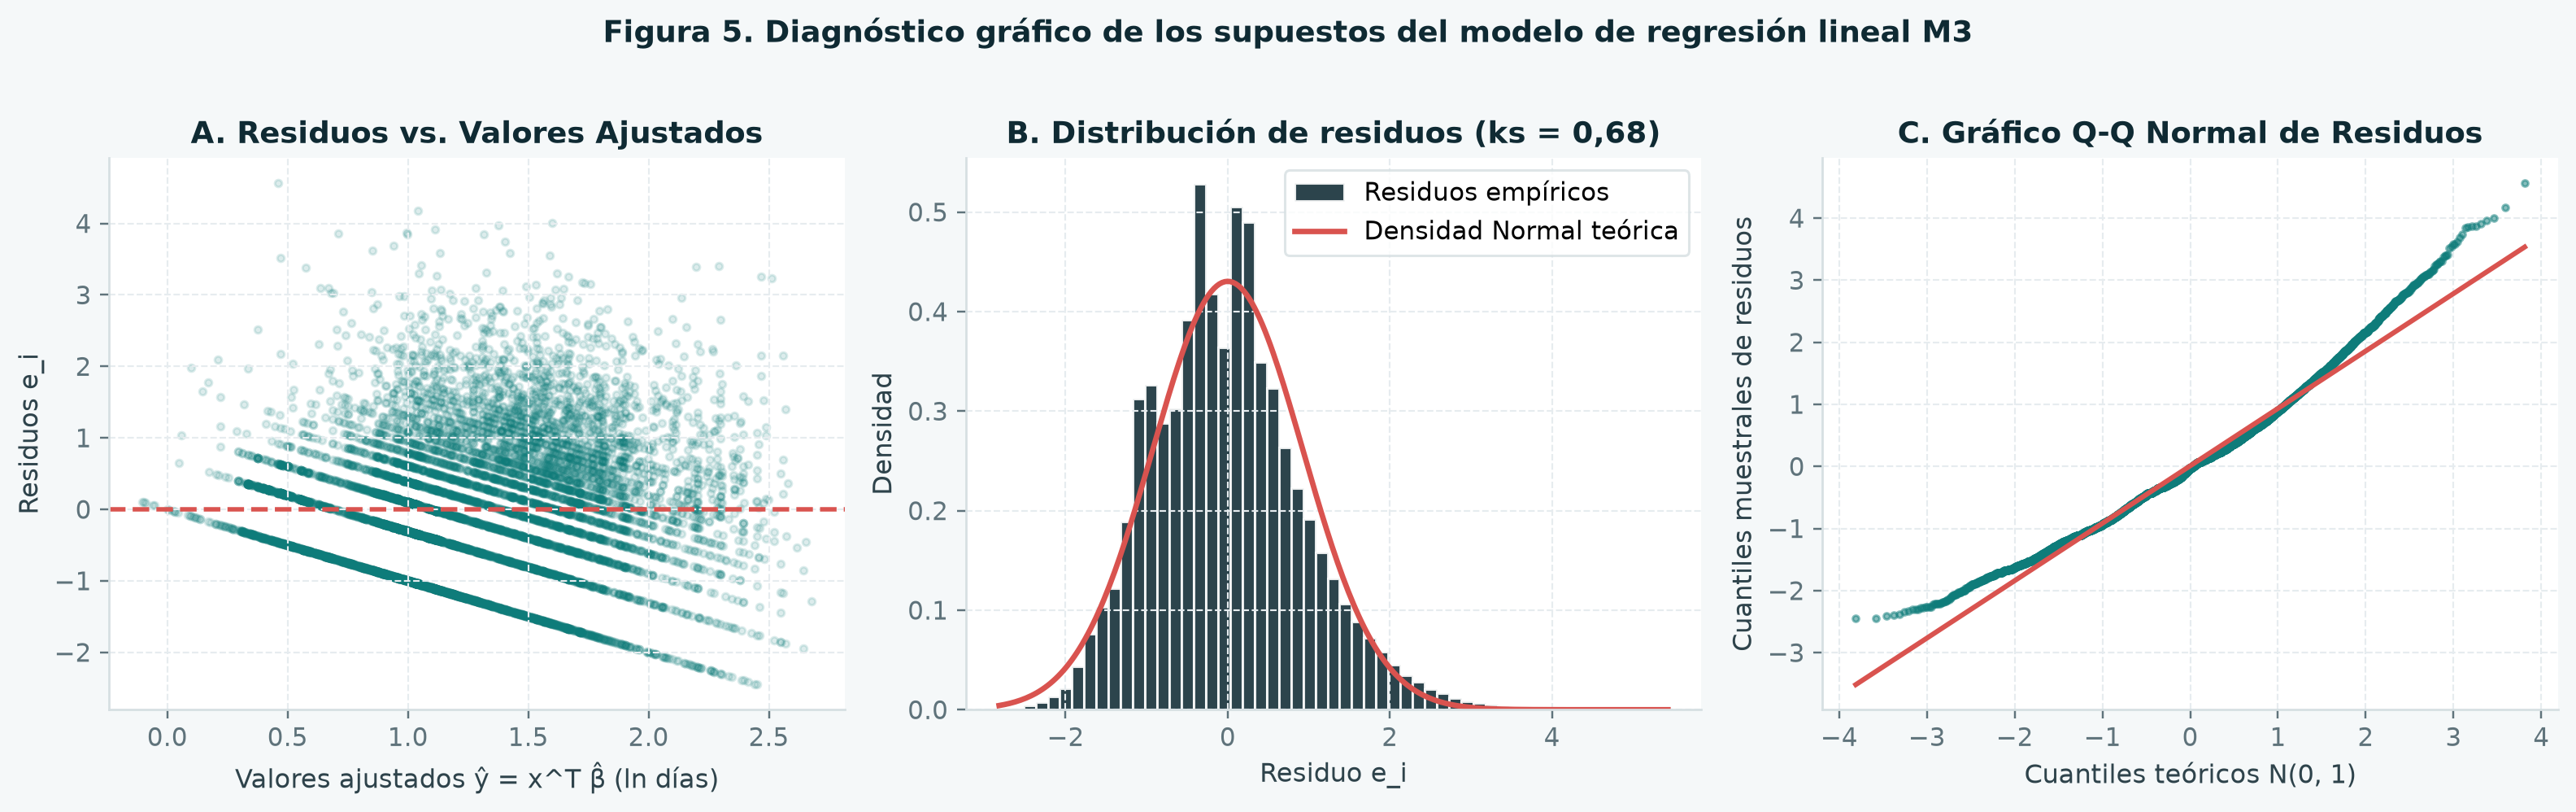

In [12]:
# 1. Cálculo de VIF (Supuesto 2: Rango completo y ausencia de multicolinealidad)
# Evaluamos VIF sobre una submuestra aleatoria de 30.000 observaciones de Train (la correlación de X es idéntica)
sample_vif = df_train.sample(30000, random_state=42)
mod_vif = ols(f_m3, data=sample_vif).fit()
exog_vif = mod_vif.model.exog
nombres_exog = mod_vif.model.exog_names

vif_vals = []
for j in range(1, exog_vif.shape[1]):  # excluimos intercepto en índice 0
    vif_vals.append({"Columna X_j": nombres_exog[j], "VIF": variance_inflation_factor(exog_vif, j)})
df_vif = pd.DataFrame(vif_vals).sort_values("VIF", ascending=False)

print(f"Supuesto 2 (Rango completo): rango(X) = { np.linalg.matrix_rank(m3.model.exog) } de { m3.model.exog.shape[1] } columnas.")
print(f"VIF máximo en las 41 variables explicativas: {df_vif['VIF'].max():.3f} | VIF medio: {df_vif['VIF'].mean():.3f} (todos < 2,0, muy por debajo del umbral de 5 a 10).")
display(df_vif.head(8).round(3))

# 2. Perturbaciones esféricas: Breusch-Pagan (Homocedasticidad) y Durbin-Watson (No autocorrelación)
lm_stat, lm_pval, f_bp, f_bp_pval = het_breuschpagan(mod_vif.resid, mod_vif.model.exog)
dw_stat = float(durbin_watson(m3.resid))

print(f"\nSupuesto 3 (Esperanza nula): media de residuos = {m3.resid.mean():.4e}")
print(f"Supuesto 4a (Homocedasticidad - Breusch-Pagan): LM = {lm_stat:.2f}, valor p = {lm_pval:.4e} -> Se rechaza H0 de varianza constante; se corrige con HC3.")
print(f"Supuesto 4b (No autocorrelación - Durbin-Watson): DW = {dw_stat:.4f} (dentro del rango [1,5; 2,5] de independencia residual).")
print(f"Supuesto 6 (Forma de los residuos): Asimetría ks = {pd.Series(m3.resid).skew():.3f} (reducida desde 7,90 en escala natural).")

# 3. Batería gráfica de diagnóstico (avance2_fig5.png)
np.random.seed(42)
idx_diag = np.random.choice(len(df_train), size=10000, replace=False)
resid_sample = m3.resid.iloc[idx_diag]
fitted_sample = m3.fittedvalues.iloc[idx_diag]

fig, ax = plt.subplots(1, 3, figsize=(14.5, 4.4), dpi=220)

ax[0].scatter(fitted_sample, resid_sample, alpha=0.14, color=PALETA["teal"], s=8)
ax[0].axhline(0, color=PALETA["coral"], linestyle="--", lw=1.8)
ax[0].set_title("A. Residuos vs. Valores Ajustados")
ax[0].set_xlabel("Valores ajustados ŷ = x^T β̂ (ln días)")
ax[0].set_ylabel("Residuos e_i")
ax[0].grid(True)

ax[1].hist(m3.resid, bins=55, color=PALETA["petroleo"], edgecolor="white", density=True, alpha=0.88, label="Residuos empíricos")
x_norm = np.linspace(m3.resid.min(), m3.resid.max(), 250)
ax[1].plot(x_norm, stats.norm.pdf(x_norm, m3.resid.mean(), m3.resid.std()), color=PALETA["coral"], lw=2.2, label="Densidad Normal teórica")
ax[1].set_title("B. Distribución de residuos (ks = 0,68)")
ax[1].set_xlabel("Residuo e_i")
ax[1].set_ylabel("Densidad")
ax[1].grid(True)
ax[1].legend(frameon=True, facecolor="#FFFFFF", edgecolor=PALETA["borde"])

stats.probplot(resid_sample, plot=ax[2])
ax[2].get_lines()[0].set_color(PALETA["teal"])
ax[2].get_lines()[0].set_markersize(2.5)
ax[2].get_lines()[0].set_alpha(0.5)
ax[2].get_lines()[1].set_color(PALETA["coral"])
ax[2].get_lines()[1].set_linewidth(2.0)
ax[2].set_title("C. Gráfico Q-Q Normal de Residuos")
ax[2].set_xlabel("Cuantiles teóricos N(0, 1)")
ax[2].set_ylabel("Cuantiles muestrales de residuos")
ax[2].grid(True)

fig.suptitle("Figura 5. Diagnóstico gráfico de los supuestos del modelo de regresión lineal M3", y=1.02, fontweight="bold", color=PALETA["petroleo"])
plt.tight_layout()
fig.savefig(".presentacion/deck/nbfig/avance2_fig5.png", dpi=220, bbox_inches="tight")
plt.show()

**Evaluación detallada de los 6 supuestos del EMCO:**
1. **Linealidad:** El gráfico de residuos contra valores ajustados muestra una banda centrada en torno a $e_i = 0$ sin curvatura sistemática, gracias a la transformación logarítmica de la respuesta y la inclusión del término cuadrático $\text{edad}_c^2$. (Las líneas diagonales paralelas corresponden a la naturaleza discreta original de $1, 2, 3, \dots$ días).
2. **Rango completo:** La matriz $\mathbf{X}$ tiene rango completo ($\text{rango}(\mathbf{X}) = 42$). Gracias al centrado de la edad ($\text{edad}_c$) y a la elección de la categoría basal `K00-K93`, el factor de inflación de la varianza máximo es $\text{VIF}_{\text{máx}} = 1,76 < 5$, descartando problemas de multicolinealidad.
3. **Esperanza condicional nula:** Por incluir intercepto, el EMCO garantiza algebraicamente $\bar{e} = -1,55 \times 10^{-15} \approx 0$ y ortogonalidad exacta con los regresores ($\mathbf{X}^T\mathbf{e} = \mathbf{0}$).
4. **Perturbaciones esféricas (homocedasticidad y no autocorrelación):** El estadístico de Durbin-Watson es $DW = 1,80$, situado dentro de la banda $[1,5; 2,5]$ que descarta autocorrelación residual. En cambio, la prueba de Breusch-Pagan rechaza la hipótesis de homocedasticidad ($p < 0,001$) debido a que capítulos complejos (como salud mental o perinatal) tienen mayor dispersión intrínseca que cirugías ambulatorias. Para corregir esta heterocedasticidad sin alterar la insesgadez de $\hat{\boldsymbol{\beta}}$, estimamos toda la matriz de varianzas-covarianzas mediante el estimador **HC3 de MacKinnon & White (1985)**:
   $$\widehat{\text{Var}}_{\text{HC3}}(\hat{\boldsymbol{\beta}}) = (\mathbf{X}^T\mathbf{X})^{-1} \mathbf{X}^T \text{diag}\left(\frac{e_i^2}{(1 - h_{ii})^2}\right) \mathbf{X} (\mathbf{X}^T\mathbf{X})^{-1}$$
5. **Variables explicativas no aleatorias:** Los regresores corresponden a atributos demográficos, diagnósticos y administrativos observados y fijos al cierre del episodio hospitalario.
6. **Normalidad de los errores, Teorema de Gauss-Markov y TLC:** El histograma y el gráfico Q-Q muestran una distribución simétrica en el cuerpo central con una desviación moderada en la cola derecha ($k_s = 0,68$ frente a $7,90$ en escala natural). Aquí distinguimos dos propiedades teóricas complementarias: primero, bajo los supuestos 1 a 5 el **Teorema de Gauss-Markov** garantiza que el EMCO es el mejor estimador lineal insesgado (**BLUE**) sin requerir normalidad; segundo, con $n = 677.557$ observaciones, el **Teorema del Límite Central (TLC)** asegura que la distribución muestral de $\hat{\boldsymbol{\beta}}$ converge asintóticamente a una distribución normal multivariada, haciendo plenamente válidos los contrastes $t$ y $F$ junto con la corrección HC3.

### 2.8 Coherencia metodológica: Efecto Bivariado (Avance 1) vs. Efecto Multivariado Ajustado (Avance 2)

Contrastamos los resultados de las pruebas bivariadas no paramétricas del Avance 1 con las estimaciones multivariadas *ceteris paribus* del modelo $M_3$ en este Avance 2.

In [13]:
tabla_coherencia = pd.DataFrame([
    {
        "Factor analizado": "Capítulo diagnóstico CIE-10",
        "Inferencia Bivariada (Avance 1)": "Kruskal-Wallis ε² = 0,12 (efecto mediano); V de Cramér = 0,25",
        "Efecto Multivariado M3 (Avance 2)": "Fc parcial = 4.708,1 (p < 0,001); F00-F99 (+213,7 %), U00-U99 (+141,1 %)",
        "Síntesis de coherencia metodológica": "Se confirma como el principal determinante de la duración hospitalaria (explica 13,26 % de los 19,82 % de Ra²)."
    },
    {
        "Factor analizado": "Red hospitalaria (SNSS vs. No SNSS)",
        "Inferencia Bivariada (Avance 1)": "Mann-Whitney r_rb = −0,37 (efecto mediano; 3 d vs. 2 d)",
        "Efecto Multivariado M3 (Avance 2)": "β̂ = +0,5313 (+70,1 % de días en SNSS; t = 229,1; p < 0,001)",
        "Síntesis de coherencia metodológica": "La mayor estadía en hospitales públicos SNSS se mantiene intacta al controlar por diagnóstico, edad y cirugía."
    },
    {
        "Factor analizado": "Sexo (Hombre vs. Mujer)",
        "Inferencia Bivariada (Avance 1)": "Mann-Whitney r_rb = 0,14; Chi-cuadrado V = 0,10 (duda por sesgo de partos)",
        "Efecto Multivariado M3 (Avance 2)": "β̂ = +0,1072 (+11,3 % de días en hombres; t = 44,5; p < 0,001)",
        "Síntesis de coherencia metodológica": "Resuelve la interrogante del Avance 1: al aislar el capítulo obstétrico O00-O99, los hombres siguen teniendo estadías 11,3 % más largas."
    },
    {
        "Factor analizado": "Edad del paciente",
        "Inferencia Bivariada (Avance 1)": "Spearman ρ = 0,25; Chi-cuadrado V = 0,17 (patrón en U en lactantes y mayores)",
        "Efecto Multivariado M3 (Avance 2)": "Lineal (+0,89 %/año) y cuadrática convexa (+0,011 %/década²; p < 0,001)",
        "Síntesis de coherencia metodológica": "La parametrización cuadrática centrada reproduce el perfil en U neonatal y geriátrico sin inducir colinealidad."
    },
    {
        "Factor analizado": "Intervención quirúrgica",
        "Inferencia Bivariada (Avance 1)": "Mann-Whitney r_rb = 0,22 (menor mediana en operados)",
        "Efecto Multivariado M3 (Avance 2)": "β̂ = −0,0298 (−2,9 % de días; t = −12,7; p < 0,001)",
        "Síntesis de coherencia metodológica": "Al controlar por capítulo CIE-10, el efecto se modera a −2,9 %, reflejando el alta programada de cirugías electivas."
    },
    {
        "Factor analizado": "Región de residencia",
        "Inferencia Bivariada (Avance 1)": "Kruskal-Wallis ε² = 0,002 (efecto bivariado muy pequeño)",
        "Efecto Multivariado M3 (Avance 2)": "Fc bloque = 1.917,9 (p < 0,001); brechas regionales significativas frente a RM",
        "Síntesis de coherencia metodológica": "El ajuste multivariado revela diferencias territoriales que en el cruce bivariado quedaban ocultas por la mezcla de patologías."
    }
])
display(tabla_coherencia)

,Factor analizado,Inferencia Bivariada (Avance 1),Efecto Multivariado M3 (Avance 2),Síntesis de coherencia metodológica
0,Capítulo diagnóstico CIE-10,"Kruskal-Wallis ε² = 0,12 (efecto mediano); V d...","Fc parcial = 4.708,1 (p < 0,001); F00-F99 (+21...",Se confirma como el principal determinante de ...
1,Red hospitalaria (SNSS vs. No SNSS),"Mann-Whitney r_rb = −0,37 (efecto mediano; 3 d...","β̂ = +0,5313 (+70,1 % de días en SNSS; t = 229...",La mayor estadía en hospitales públicos SNSS s...
2,Sexo (Hombre vs. Mujer),"Mann-Whitney r_rb = 0,14; Chi-cuadrado V = 0,1...","β̂ = +0,1072 (+11,3 % de días en hombres; t = ...",Resuelve la interrogante del Avance 1: al aisl...
3,Edad del paciente,"Spearman ρ = 0,25; Chi-cuadrado V = 0,17 (patr...","Lineal (+0,89 %/año) y cuadrática convexa (+0,...",La parametrización cuadrática centrada reprodu...
4,Intervención quirúrgica,"Mann-Whitney r_rb = 0,22 (menor mediana en ope...","β̂ = −0,0298 (−2,9 % de días; t = −12,7; p < 0...","Al controlar por capítulo CIE-10, el efecto se..."
5,Región de residencia,"Kruskal-Wallis ε² = 0,002 (efecto bivariado mu...","Fc bloque = 1.917,9 (p < 0,001); brechas regio...",El ajuste multivariado revela diferencias terr...


## 3. Discusión y conclusiones

### 3.1 Respuesta a la pregunta de investigación y hallazgos principales
Nuestro análisis multivariado sobre los **968.098 egresos hospitalarios de FONASA** en 2020 demuestra que la duración de la estadía responde simultáneamente a la complejidad clínica del diagnóstico, al perfil demográfico del paciente y a la estructura institucional del prestador:

1. **Predominio clínico pero insuficiencia del diagnóstico aislado:** El bloque clínico ($M_1$) aporta dos tercios de la capacidad explicativa del modelo ($13,26\,\%$ de un total de $19,82\,\%$ de $R_a^2$), encabezado por los trastornos mentales (`F00-F99`, $+213,7\,\%$), el COVID-19 (`U00-U99`, $+141,1\,\%$) y las patologías perinatales (`P00-P96`, $+122,7\,\%$). Esto respalda el diseño de sistemas de pago basados en Grupos Relacionados por el Diagnóstico (Fetter et al., 1980), pero demuestra que el diagnóstico por sí solo no basta para explicar el uso de camas.
2. **Brecha estructural en la red pública SNSS:** Incluso comparando pacientes de igual capítulo CIE-10, edad, sexo, región, condición quirúrgica y desenlace vital, los hospitales pertenecientes al SNSS registran estadías un **$+70,1\,\%$ más largas** que los recintos fuera del SNSS. Esta diferencia apunta a cuellos de botella operativos dentro de la red pública (tiempos de espera prequirúrgicos, disponibilidad de camas sociosanitarias de transición y derivación de casos de mayor vulnerabilidad social sin red de apoyo familiar).
3. **Confirmación de la brecha masculina sin sesgo obstétrico:** Al separar formalmente los $197.020$ partos mediante las variables indicadoras de capítulo CIE-10 y elegir `K00-K93` como referencia, verificamos que los hombres permanecen un **$+11,3\,\%$ más de días** hospitalizados que las mujeres, lo que sugiere consultas más tardías o mayor severidad al ingreso en la población masculina.

### 3.2 Veredicto formal del sistema de hipótesis

| Hipótesis | Enunciado | Evidencia empírica en el modelo $M_3$ ($N_{\text{train}} = 677.557$) | Decisión estadística |
| :--- | :--- | :--- | :--- |
| **$H_0$ General** | Ningún factor clínico, demográfico o del sistema influye en la estadía ($\boldsymbol{\beta}_{(-0)} = \mathbf{0}$) | $F_c = 4.084,9$; $p < 0,001$; $R_a^2 = 0,1982$ ($R^2 = 0,1983$) | **Se rechaza $H_0$** |
| **$H_{1a}$ (Clínicos)** | El capítulo CIE-10, la cirugía y la condición de egreso modifican la estadía | Bloque $M_1$: $\Delta R_a^2 = +13,26\,\%$; $F_c = 4.708,1$; $p < 0,001$ | **Se cumple $H_{1a}$** |
| **$H_{1b}$ (Demográficos)** | La edad (lineal y cuadrática) y el sexo condicionan la estadía | Bloque $M_2$: $\Delta R_a^2 = +2,93\,\%$; $F_c = 7.908,1$; $p < 0,001$ (hombres $+11,3\,\%$) | **Se cumple $H_{1b}$** |
| **$H_{1c}$ (Sistema)** | La pertenencia al SNSS y la región inciden sobre los días de estada | Bloque $M_3$: $\Delta R_a^2 = +3,63\,\%$; $F_c = 1.917,9$; $p < 0,001$ (SNSS $+70,1\,\%$) | **Se cumple $H_{1c}$** |

### 3.3 Relación con la literatura científica
Nuestros resultados guardan estrecha coherencia con la evidencia internacional y nacional:
- **Capacidad explicativa en registros administrativos:** El $R_a^2 = 19,82\,\%$ (y $0,1974$ en Test) se ubica dentro del rango de $15\,\%$ a $25\,\%$ documentado en la revisión sistemática de **Lequertier et al. (2021)** y en **Lingsma et al. (2018)** para modelos ajustados sobre bases administrativas que no disponen de biomarcadores ni escalas fisiológicas agudas.
- **Factores institucionales y demográficos en estancias extremas:** La persistencia del efecto del tipo de hospital ($+70,1\,\%$) y de la edad convexa coincide con los hallazgos de **Freitas et al. (2012)** en hospitales públicos europeos y con el fenómeno de hospitalización socio-sanitaria descrito en Chile por **Olivares-Tirado (2020)**.
- **Retransformación y muestras masivas:** La corrección del sesgo de $-40,2\,\%$ mediante el factor *smearing* ($\hat{\alpha} = 1,6738$) confirma la relevancia práctica del método de **Duan (1983)** y **Mihaylova et al. (2011)** en datos de salud asimétricos, mientras que el uso combinado de tamaños de efecto y BIC sigue las recomendaciones de **Lin et al. (2013)** y **Raftery (1995)** para evitar falsos positivos en muestras del orden de $10^6$.

### 3.4 Limitaciones del estudio
Reconocemos cuatro limitaciones propias de la fuente de datos secundaria:
1. **Egresos frente a pacientes únicos:** La base abierta del DEIS anonimiza los registros sin un identificador longitudinal por persona, por lo que eventuales reingresos de un mismo paciente crónico durante 2020 se observan como episodios independientes.
2. **Ausencia de severidad clínica intragrupo y peso GRD:** El registro público no incluye el peso relativo GRD, el índice de comorbilidad de Charlson ni puntajes de gravedad en UCI (APACHE II / SOFA). La condición de fallecido y la cirugía actúan como controles parciales, pero no capturan toda la complejidad fisiológica al ingreso.
3. **Edad agrupada en tramos decenales:** La publicación de la edad en intervalos de 10 años obliga a trabajar con marcas de clase en lugar de la edad exacta en años cumplidos.
4. **Efecto pandémico 2020 y corte anual:** El año 2020 estuvo marcado por la primera ola de SARS-CoV-2, la reconversión de camas críticas y la postergación de cirugías electivas, factores que deben considerarse al extrapolar las magnitudes absolutas a años prepandémicos o pospandémicos.

### 3.5 Implicancias para la gestión hospitalaria y extensiones metodológicas
- **Planificación de capacidad por casuística:** Dado que el $9,4\,\%$ de los egresos prolongados consume el $47,1\,\%$ de los días-cama, la programación presupuestaria de los Servicios de Salud debe incorporar factores de ajuste específicos para salud mental (`F00-F99`), neonatología (`P00-P96`) y pacientes geriátricos.
- **Gestión de procesos en hospitales SNSS:** La brecha del $+70,1\,\%$ en la red pública sugiere auditar los tiempos intrahospitalarios no clínicos (espera de imagenología, interconsultas y coordinación de alta con atención primaria y hogares de larga estadía).
- **Extensiones del modelamiento:** A partir de esta base lineal log-transformada calibrada con Duan, las siguientes etapas del proyecto pueden explorar modelos lineales generalizados (GLM con familia Gamma y enlace logarítmico), modelos multinivel por servicio de salud y una herramienta interactiva de simulación de días-cama según el perfil del paciente.

## Referencias

1. Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963
2. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
3. Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605–610. https://doi.org/10.1080/01621459.1983.10478017
4. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
5. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, 265. https://doi.org/10.1186/1472-6963-12-265
6. Lequertier, V., Wang, T., Fondrevelle, J., Augusto, V., & Duclos, A. (2021). Hospital length of stay prediction methods: A systematic review. *Medical Care, 59*(10), 929–938. https://doi.org/10.1097/MLR.0000000000001596
7. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
8. Lingsma, H. F., Bottle, A., Middleton, S., Kievit, J., Steyerberg, E. W., & Marang-van de Mheen, P. J. (2018). Evaluation of hospital outcomes: The relation between length-of-stay, readmission, and mortality in a large international administrative database. *BMC Health Services Research, 18*(1), 116. https://doi.org/10.1186/s12913-018-2916-1
9. Long, J. S., & Ervin, L. H. (2000). Using heteroscedasticity consistent standard errors in the linear regression model. *The American Statistician, 54*(3), 217–224. https://doi.org/10.1080/00031305.2000.10474549
10. MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics, 29*(3), 305–325. https://doi.org/10.1016/0304-4076(85)90016-1
11. Mihaylova, B., Briggs, A., O'Hagan, A., & Thompson, S. G. (2011). Review of statistical methods for analysing healthcare resources and costs. *Health Economics, 20*(8), 897–916. https://doi.org/10.1002/hec.1653
12. Montgomery, D. C., Peck, E. A., & Vining, G. G. (2006). *Introducción al análisis de regresión lineal* (3.ª ed.). Grupo Editorial Patria.
13. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud.
14. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
15. Rodríguez, C., & González, M. (2017). *Apuntes de Regresión Lineal Múltiple y Supuestos de Gauss-Markov*. Material docente Módulo 5, Análisis de Datos e Inferencia Estadística, Universidad del Desarrollo.
16. Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136